<a href="https://colab.research.google.com/github/nurtuasikal-cmyk/Project-UTS-Kelompok-7/blob/main/Jurnal_UAS_Kelompok_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Instalasi dan import library

In [4]:
!pip -q install statsmodels scikit-learn openpyxl seaborn

import warnings, os, itertools, json
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from scipy.stats import jarque_bera

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
SEASONAL_PERIOD = 12
TRAIN_RATIO = 0.80

# Atur None untuk seluruh provinsi. Untuk uji coba awal, isi misalnya ['MALUKU'].
PROVINCE_FILTER = None

# Grid dibuat ringkas agar dapat dijalankan di Colab. Dapat diperluas setelah uji coba.
ORDER_CANDIDATES = [(1,1,1), (1,1,0), (0,1,1), (0,1,0)]
SEASONAL_CANDIDATES = [
    (1,1,1,SEASONAL_PERIOD),
    (0,1,1,SEASONAL_PERIOD)
]

print("Library siap.")


Library siap.


##1. Upload dan baca dataset

In [5]:
uploaded = files.upload()  # Pilih Data Padi.xlsx
file_name = next(iter(uploaded.keys()))
raw = pd.read_excel(file_name)

print("Ukuran data:", raw.shape)
display(raw.head())
print("\nKolom:", raw.columns.tolist())

Saving Data Padi.xlsx to Data Padi.xlsx
Ukuran data: (3952, 6)


,Provinsi,Tahun,Bulan,Y,X,Curah_Hujan_mm
0,ACEH,2018,Januari,76118.47,14541.53,271.773066
1,ACEH,2018,Februari,142876.76,27075.77,107.421202
2,ACEH,2018,Maret,375841.91,66403.96,173.163008
3,ACEH,2018,April,336742.80,58507.03,235.422620
4,ACEH,2018,Mei,96372.36,16867.65,241.453734



Kolom: ['Provinsi', 'Tahun', 'Bulan', 'Y', 'X', 'Curah_Hujan_mm']


##2. Preprocessing dan validasi panel

In [6]:
# Sesuaikan nama kolom bila file sumber berbeda.
required = ['Provinsi', 'Tahun', 'Bulan', 'Y', 'X', 'Curah_Hujan_mm']
missing_cols = [c for c in required if c not in raw.columns]
if missing_cols:
    raise ValueError(f"Kolom berikut tidak ditemukan: {missing_cols}")

# Dataset menggunakan ejaan "Nopember" dan memiliki spasi pada "Oktober ".
month_map = {
    'januari':1, 'februari':2, 'maret':3, 'april':4, 'mei':5, 'juni':6,
    'juli':7, 'agustus':8, 'september':9, 'oktober':10,
    'nopember':11, 'november':11, 'desember':12
}

df = raw.copy()
df['Provinsi'] = df['Provinsi'].astype(str).str.strip().str.upper()
df['bulan_num'] = (
    df['Bulan'].astype(str).str.strip().str.lower().map(month_map)
)

if df['bulan_num'].isna().any():
    print("Nama bulan yang belum dikenali:",
          df.loc[df['bulan_num'].isna(), 'Bulan'].unique())
    raise ValueError("Ada nama bulan yang tidak dikenali. Periksa kolom Bulan.")

df['Tanggal'] = pd.to_datetime({
    'year': df['Tahun'].astype(int),
    'month': df['bulan_num'].astype(int),
    'day': 1
})
df = df.rename(columns={'X':'X1', 'Curah_Hujan_mm':'X2'})
for c in ['Y','X1','X2']:
    df[c] = pd.to_numeric(df[c], errors='coerce')

print("Preprocessing berhasil!")
print("Missing values:\n", df[['Provinsi','Tanggal','Y','X1','X2']].isna().sum())
print("Duplikat provinsi-tanggal:", df.duplicated(['Provinsi','Tanggal']).sum())

if df[['Provinsi','Tanggal','Y','X1','X2']].isna().any().any():
    raise ValueError("Terdapat data kosong/tidak valid. Periksa dan tangani terlebih dahulu.")
if df.duplicated(['Provinsi','Tanggal']).any():
    raise ValueError("Terdapat duplikasi provinsi-tanggal.")

df = df.sort_values(['Provinsi','Tanggal']).reset_index(drop=True)

province_counts = df.groupby('Provinsi').size()
print("Jumlah provinsi:", df['Provinsi'].nunique())
print("Jumlah observasi per provinsi:\n", province_counts.value_counts().sort_index())

for prov, g in df.groupby('Provinsi'):
    expected = pd.date_range(g['Tanggal'].min(), g['Tanggal'].max(), freq='MS')
    if not g['Tanggal'].reset_index(drop=True).equals(pd.Series(expected)):
        print("PERINGATAN: urutan tanggal tidak lengkap/berurutan untuk", prov)

if PROVINCE_FILTER is not None:
    df = df[df['Provinsi'].isin([p.upper() for p in PROVINCE_FILTER])].copy()

provinces = sorted(df['Provinsi'].unique())
print(f"Provinsi dianalisis: {len(provinces)}")
display(df.groupby('Provinsi').agg(
    n=('Y','size'), awal=('Tanggal','min'), akhir=('Tanggal','max'),
    rata_produksi=('Y','mean')
).head(10))


Preprocessing berhasil!
Missing values:
 Provinsi    0
Tanggal     0
Y           0
X1          0
X2          0
dtype: int64
Duplikat provinsi-tanggal: 0
Jumlah provinsi: 38
Jumlah observasi per provinsi:
 104    38
Name: count, dtype: int64
Provinsi dianalisis: 38


,n,awal,akhir,rata_produksi
Provinsi,,,,
ACEH,104,2018-01-01,2026-08-01,135304.184904
BALI,104,2018-01-01,2026-08-01,51443.245769
BANTEN,104,2018-01-01,2026-08-01,140809.162308
BENGKULU,104,2018-01-01,2026-08-01,23409.349808
DI YOGYAKARTA,104,2018-01-01,2026-08-01,45496.376058
DKI JAKARTA,104,2018-01-01,2026-08-01,247.088750
GORONTALO,104,2018-01-01,2026-08-01,21032.537596
JAMBI,104,2018-01-01,2026-08-01,27037.837596
JAWA BARAT,104,2018-01-01,2026-08-01,779544.340769


##3. Eksplorasi data dan pembagian training-testing

In [7]:
!pip -q install plotly

import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display, Markdown

# Pastikan urutan waktu dan tipe data benar
eda = df.copy()
eda['Tahun'] = eda['Tanggal'].dt.year
eda['Bulan_num'] = eda['Tanggal'].dt.month
month_names = ['Januari','Februari','Maret','April','Mei','Juni',
               'Juli','Agustus','September','Oktober','November','Desember']
eda['Nama_Bulan'] = pd.Categorical(
    eda['Bulan_num'].map(dict(enumerate(month_names, start=1))),
    categories=month_names, ordered=True
)

# ---------- A. Kartu ringkasan ----------
n_prov = eda['Provinsi'].nunique()
n_obs = len(eda)
date_min, date_max = eda['Tanggal'].min(), eda['Tanggal'].max()
n_months = eda.groupby('Provinsi')['Tanggal'].nunique().median()

summary_cards = pd.DataFrame({
    'Indikator': ['Jumlah provinsi','Total observasi','Periode pengamatan','Median bulan/provinsi'],
    'Nilai': [f'{n_prov:,}', f'{n_obs:,}',
              f'{date_min:%b %Y} – {date_max:%b %Y}', f'{int(n_months)} bulan']
})
display(Markdown("### A. Ringkasan dataset"))
display(summary_cards.style.hide(axis='index').set_properties(**{
    'font-size':'13pt', 'text-align':'center'
}).set_table_styles([{'selector':'th','props':[('background-color','#17365D'),
                                               ('color','white'),
                                               ('text-align','center')]}]))

# ---------- B. Statistik deskriptif ----------
display(Markdown("### B. Statistik deskriptif variabel"))
desc = eda[['Y','X1','X2']].describe().T
desc = desc.rename(columns={
    'count':'Jumlah','mean':'Rata-rata','std':'Std. Deviasi',
    'min':'Minimum','25%':'Q1','50%':'Median','75%':'Q3','max':'Maksimum'
})
display(desc.round(2).style.background_gradient(cmap='Blues', axis=0).format('{:,.2f}'))

# ---------- C. Tren nasional per bulan ----------
# Y dan X1 dijumlahkan antarprovinsi; X2 dirata-ratakan antarprovinsi.
national = eda.groupby('Tanggal', as_index=False).agg(
    Produksi_Nasional=('Y','sum'),
    Luas_Panen_Nasional=('X1','sum'),
    Curah_Hujan_Rata2=('X2','mean')
)

display(Markdown("### C. Perkembangan indikator nasional"))
fig = make_subplots(rows=3, cols=1, shared_xaxes=True, vertical_spacing=.09,
                    subplot_titles=('Produksi padi nasional','Luas panen nasional',
                                    'Rata-rata curah hujan antarprovinsi'))
fig.add_trace(go.Scatter(x=national['Tanggal'], y=national['Produksi_Nasional'],
                         mode='lines', name='Produksi', line=dict(width=2.5)), row=1,col=1)
fig.add_trace(go.Scatter(x=national['Tanggal'], y=national['Luas_Panen_Nasional'],
                         mode='lines', name='Luas panen', line=dict(width=2.5)), row=2,col=1)
fig.add_trace(go.Scatter(x=national['Tanggal'], y=national['Curah_Hujan_Rata2'],
                         mode='lines', name='Curah hujan', line=dict(width=2.5)), row=3,col=1)
fig.update_layout(height=780, template='plotly_white', showlegend=False,
                  title='Dinamika produksi, luas panen, dan curah hujan')
fig.update_xaxes(title_text='Tahun-bulan', row=3, col=1)
fig.show()

# ---------- D. Perbandingan antarprovinsi ----------
display(Markdown("### D. Perbandingan produksi antarprovinsi"))
prov_summary = eda.groupby('Provinsi', as_index=False).agg(
    Total_Produksi=('Y','sum'),
    Rata2_Produksi_Bulanan=('Y','mean'),
    Total_Luas_Panen=('X1','sum'),
    Rata2_Curah_Hujan=('X2','mean')
).sort_values('Total_Produksi', ascending=False)

fig = px.bar(prov_summary.sort_values('Total_Produksi', ascending=True),
             x='Total_Produksi', y='Provinsi', orientation='h',
             color='Total_Produksi', color_continuous_scale='Blues',
             title='Total produksi padi selama periode pengamatan per provinsi',
             labels={'Total_Produksi':'Total produksi','Provinsi':'Provinsi'})
fig.update_layout(height=900, template='plotly_white')
fig.show()

top_prov = prov_summary.head(6)['Provinsi'].tolist()
fig = px.line(eda[eda['Provinsi'].isin(top_prov)].sort_values('Tanggal'),
              x='Tanggal', y='Y', color='Provinsi',
              title='Tren produksi bulanan — 6 provinsi dengan total produksi tertinggi',
              labels={'Y':'Produksi padi','Tanggal':'Periode'})
fig.update_layout(template='plotly_white', height=520)
fig.show()

# ---------- E. Pola musiman ----------
display(Markdown("### E. Pola musiman produksi padi"))
seasonal = eda.groupby('Bulan_num', as_index=False).agg(
    Rata2_Produksi=('Y','mean')
)
seasonal['Bulan'] = seasonal['Bulan_num'].map(dict(enumerate(month_names, start=1)))
fig = px.bar(seasonal, x='Bulan', y='Rata2_Produksi',
             category_orders={'Bulan':month_names},
             title='Rata-rata produksi bulanan antarprovinsi',
             color='Rata2_Produksi', color_continuous_scale='Tealgrn')
fig.update_layout(template='plotly_white', height=430)
fig.show()

heat = eda.pivot_table(index='Tahun', columns='Bulan_num', values='Y',
                       aggfunc='mean')
heat = heat.reindex(columns=range(1,13))
fig = px.imshow(heat, aspect='auto', color_continuous_scale='YlGn',
                labels=dict(x='Bulan', y='Tahun', color='Rata-rata Y'),
                x=month_names, title='Heatmap rata-rata produksi: tahun × bulan')
fig.update_layout(template='plotly_white', height=480)
fig.show()

# ---------- F. Distribusi, pencilan, dan bentuk sebaran ----------
display(Markdown("### F. Distribusi dan pencilan"))
long_vars = eda[['Y','X1','X2']].melt(var_name='Variabel', value_name='Nilai')
fig = px.histogram(long_vars, x='Nilai', facet_col='Variabel',
                   facet_col_wrap=1, nbins=45, color='Variabel',
                   title='Distribusi setiap variabel')
fig.update_layout(template='plotly_white', height=850, showlegend=False)
fig.show()

fig = px.box(long_vars, x='Variabel', y='Nilai', color='Variabel',
             points='outliers', title='Boxplot untuk pemeriksaan pencilan')
fig.update_layout(template='plotly_white', height=480, showlegend=False)
fig.show()

# ---------- G. Hubungan antarvariabel ----------
display(Markdown("### G. Hubungan antara Y, X1, dan X2"))
corr = eda[['Y','X1','X2']].corr(method='pearson')
fig = px.imshow(corr, text_auto='.2f', aspect='auto',
                color_continuous_scale='RdBu_r', zmin=-1, zmax=1,
                title='Korelasi Pearson gabungan seluruh provinsi')
fig.update_layout(template='plotly_white', height=450)
fig.show()

# Scatter menggunakan sampel agar grafik tetap responsif.
scatter_sample = eda.sample(min(1800, len(eda)), random_state=42)
fig = px.scatter(scatter_sample, x='X1', y='Y', color='X2',
                 hover_data=['Provinsi','Tanggal'],
                 opacity=.65, color_continuous_scale='Viridis',
                 title='Hubungan luas panen (X1) dengan produksi (Y); warna menunjukkan curah hujan')
fig.update_layout(template='plotly_white', height=550)
fig.show()

fig = px.scatter(scatter_sample, x='X2', y='Y', color='Provinsi',
                 opacity=.45, title='Hubungan curah hujan (X2) dengan produksi (Y)',
                 labels={'X2':'Curah hujan','Y':'Produksi padi'})
fig.update_layout(template='plotly_white', height=550, showlegend=False)
fig.show()

# Korelasi per provinsi: lebih informatif untuk melihat heterogenitas hubungan.
within_corr = pd.DataFrame([
    {'Provinsi': prov,
     'Korelasi_Y_X1': grp['Y'].corr(grp['X1']),
     'Korelasi_Y_X2': grp['Y'].corr(grp['X2'])}
    for prov, grp in eda.groupby('Provinsi')
])
display(Markdown("### H. Korelasi per provinsi"))
display(within_corr.round(3).style.background_gradient(cmap='RdYlGn', vmin=-1, vmax=1))

fig = px.bar(within_corr.sort_values('Korelasi_Y_X1'),
             x='Korelasi_Y_X1', y='Provinsi', orientation='h',
             title='Korelasi Y dengan X1 pada masing-masing provinsi',
             color='Korelasi_Y_X1', color_continuous_scale='RdYlGn',
             range_color=[-1,1])
fig.update_layout(template='plotly_white', height=900)
fig.show()

# ---------- I. Ringkasan temuan otomatis ----------
display(Markdown("### I. Ringkasan eksplorasi otomatis"))
print("Provinsi dengan total produksi terbesar:", prov_summary.iloc[0]['Provinsi'])
print("Provinsi dengan total produksi terkecil:", prov_summary.iloc[-1]['Provinsi'])
print("Bulan dengan rata-rata produksi tertinggi:",
      seasonal.loc[seasonal['Rata2_Produksi'].idxmax(), 'Bulan'])
print("Korelasi pooled Y-X1:", round(corr.loc['Y','X1'], 3))
print("Korelasi pooled Y-X2:", round(corr.loc['Y','X2'], 3))
print("Catatan: korelasi bukan kausalitas; interpretasikan dengan mempertimbangkan perbedaan skala antarprovinsi.")

# ---------- J. Pembagian training-testing ----------
# Pembagian dilakukan berdasarkan urutan waktu untuk setiap provinsi.
panel = {}
for prov in provinces:
    gp = df[df['Provinsi'] == prov].sort_values('Tanggal').set_index('Tanggal')
    n_train = int(len(gp) * TRAIN_RATIO)
    if n_train <= 2 * SEASONAL_PERIOD or len(gp) - n_train < 1:
        raise ValueError(f"Observasi training terlalu sedikit untuk {prov}.")
    panel[prov] = {
        'full': gp,
        'train': gp.iloc[:n_train].copy(),
        'test': gp.iloc[n_train:].copy()
    }

split_table = pd.DataFrame([
    {'Provinsi':p, 'N':len(v['full']), 'Training':len(v['train']),
     'Testing':len(v['test']), 'Akhir_training':v['train'].index.max(),
     'Awal_testing':v['test'].index.min()}
    for p,v in panel.items()
])
display(Markdown("### K. Pembagian training dan testing per provinsi"))
display(split_table)


### A. Ringkasan dataset

Indikator,Nilai
Jumlah provinsi,38
Total observasi,"3,952"
Periode pengamatan,Jan 2018 – Aug 2026
Median bulan/provinsi,104 bulan


### B. Statistik deskriptif variabel

,Jumlah,Rata-rata,Std. Deviasi,Minimum,Q1,Median,Q3,Maksimum
Y,"3,952.00","123,694.44","263,798.98",0.00,"3,535.04","28,889.32","106,515.21","2,449,941.28"
X1,"3,952.00","23,653.72","47,076.42",0.00,959.86,"6,385.88","22,642.96","415,952.10"
X2,"3,952.00",236.31,116.54,4.59,157.75,239.26,311.97,780.96


### C. Perkembangan indikator nasional

### D. Perbandingan produksi antarprovinsi

... (5 outputs left out)

### I. Ringkasan eksplorasi otomatis

Provinsi dengan total produksi terbesar: JAWA TIMUR
Provinsi dengan total produksi terkecil: KEPULAUAN RIAU
Bulan dengan rata-rata produksi tertinggi: Maret
Korelasi pooled Y-X1: 0.996
Korelasi pooled Y-X2: -0.051
Catatan: korelasi bukan kausalitas; interpretasikan dengan mempertimbangkan perbedaan skala antarprovinsi.


### K. Pembagian training dan testing per provinsi

,Provinsi,N,Training,Testing,Akhir_training,Awal_testing
0,ACEH,104,83,21,2024-11-01,2024-12-01
1,BALI,104,83,21,2024-11-01,2024-12-01
2,BANTEN,104,83,21,2024-11-01,2024-12-01
3,BENGKULU,104,83,21,2024-11-01,2024-12-01
4,DI YOGYAKARTA,104,83,21,2024-11-01,2024-12-01
5,DKI JAKARTA,104,83,21,2024-11-01,2024-12-01
6,GORONTALO,104,83,21,2024-11-01,2024-12-01
7,JAMBI,104,83,21,2024-11-01,2024-12-01
8,JAWA BARAT,104,83,21,2024-11-01,2024-12-01
9,JAWA TENGAH,104,83,21,2024-11-01,2024-12-01


##4. Uji stasioneritas ADF dan KPSS

In [8]:
def stationarity_tests(series):
    s = pd.Series(series).dropna().astype(float)
    out = {}
    try:
        out['ADF_stat'] = adfuller(s, autolag='AIC')[0]
        out['ADF_pvalue'] = adfuller(s, autolag='AIC')[1]
    except Exception:
        out['ADF_stat'], out['ADF_pvalue'] = np.nan, np.nan
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            k = kpss(s, regression='c', nlags='auto')
        out['KPSS_stat'], out['KPSS_pvalue'] = k[0], k[1]
    except Exception:
        out['KPSS_stat'], out['KPSS_pvalue'] = np.nan, np.nan
    out['Kesimpulan_ADF'] = 'Stasioner' if pd.notna(out['ADF_pvalue']) and out['ADF_pvalue'] < .05 else 'Belum stasioner/tidak cukup bukti'
    out['Kesimpulan_KPSS'] = 'Stasioner' if pd.notna(out['KPSS_pvalue']) and out['KPSS_pvalue'] > .05 else 'Belum stasioner'
    return out

stationarity_rows = []
for prov in provinces:
    y = panel[prov]['train']['Y']
    for label, series in [
        ('Y_asli', y),
        ('Y_diff1', y.diff().dropna()),
        ('Y_diff1_seasonal12', y.diff().diff(SEASONAL_PERIOD).dropna())
    ]:
        stationarity_rows.append({'Provinsi':prov, 'Seri':label, **stationarity_tests(series)})

stationarity_table = pd.DataFrame(stationarity_rows)
display(stationarity_table.head(15))
stationarity_table.to_csv('hasil_uji_stasioneritas.csv', index=False)


,Provinsi,Seri,ADF_stat,ADF_pvalue,KPSS_stat,KPSS_pvalue,Kesimpulan_ADF,Kesimpulan_KPSS
0,ACEH,Y_asli,-2.234104,1.941012e-01,0.099802,0.10000,Belum stasioner/tidak cukup bukti,Stasioner
1,ACEH,Y_diff1,-9.212227,1.874337e-15,0.106454,0.10000,Stasioner,Stasioner
2,ACEH,Y_diff1_seasonal12,-8.148847,9.820111e-13,0.133354,0.10000,Stasioner,Stasioner
3,BALI,Y_asli,-1.314384,6.225663e-01,0.131424,0.10000,Belum stasioner/tidak cukup bukti,Stasioner
4,BALI,Y_diff1,-7.052312,5.486283e-10,0.192198,0.10000,Stasioner,Stasioner
5,BALI,Y_diff1_seasonal12,-6.309266,3.264981e-08,0.266456,0.10000,Stasioner,Stasioner
6,BANTEN,Y_asli,-2.059383,2.611573e-01,0.034366,0.10000,Belum stasioner/tidak cukup bukti,Stasioner
7,BANTEN,Y_diff1,-6.498895,1.175297e-08,0.346834,0.10000,Stasioner,Stasioner
8,BANTEN,Y_diff1_seasonal12,-7.250691,1.783361e-10,0.136324,0.10000,Stasioner,Stasioner
9,BENGKULU,Y_asli,-5.997559,1.687367e-07,0.044987,0.10000,Stasioner,Stasioner


##5. Identifikasi ACF dan PACF untuk SELURUH PROVINSI

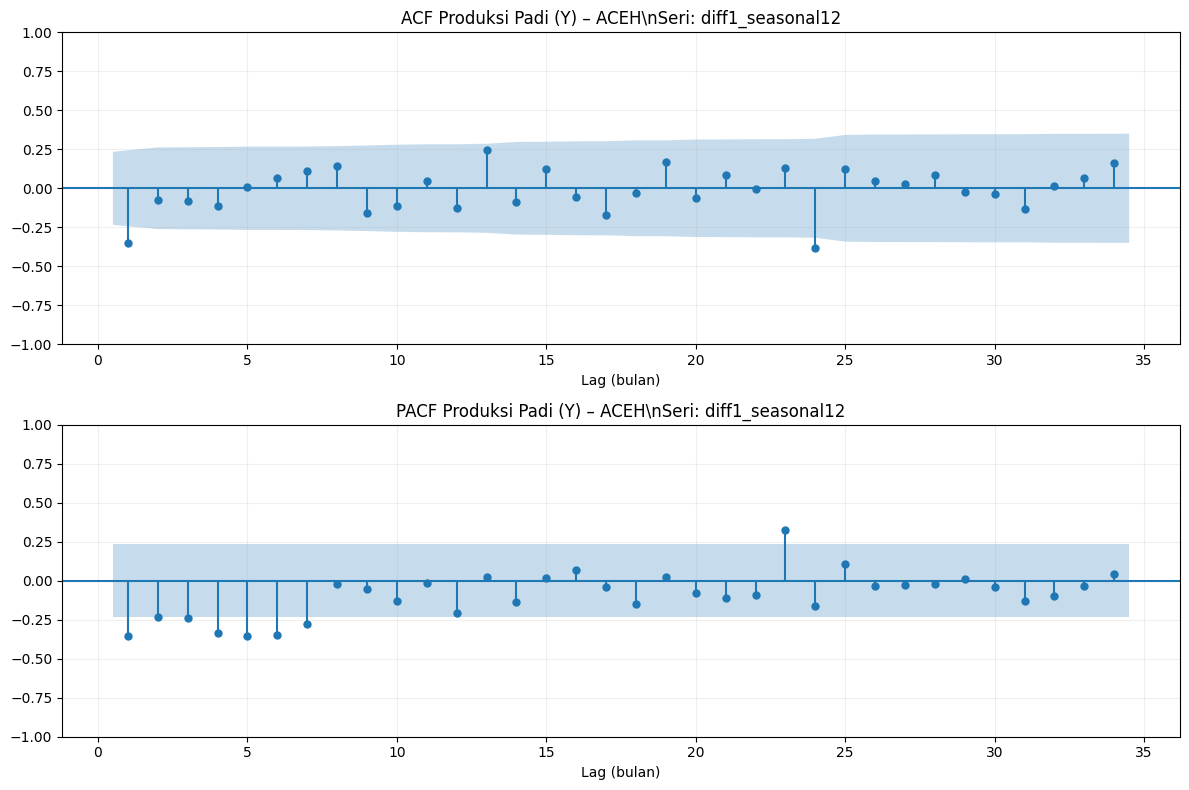

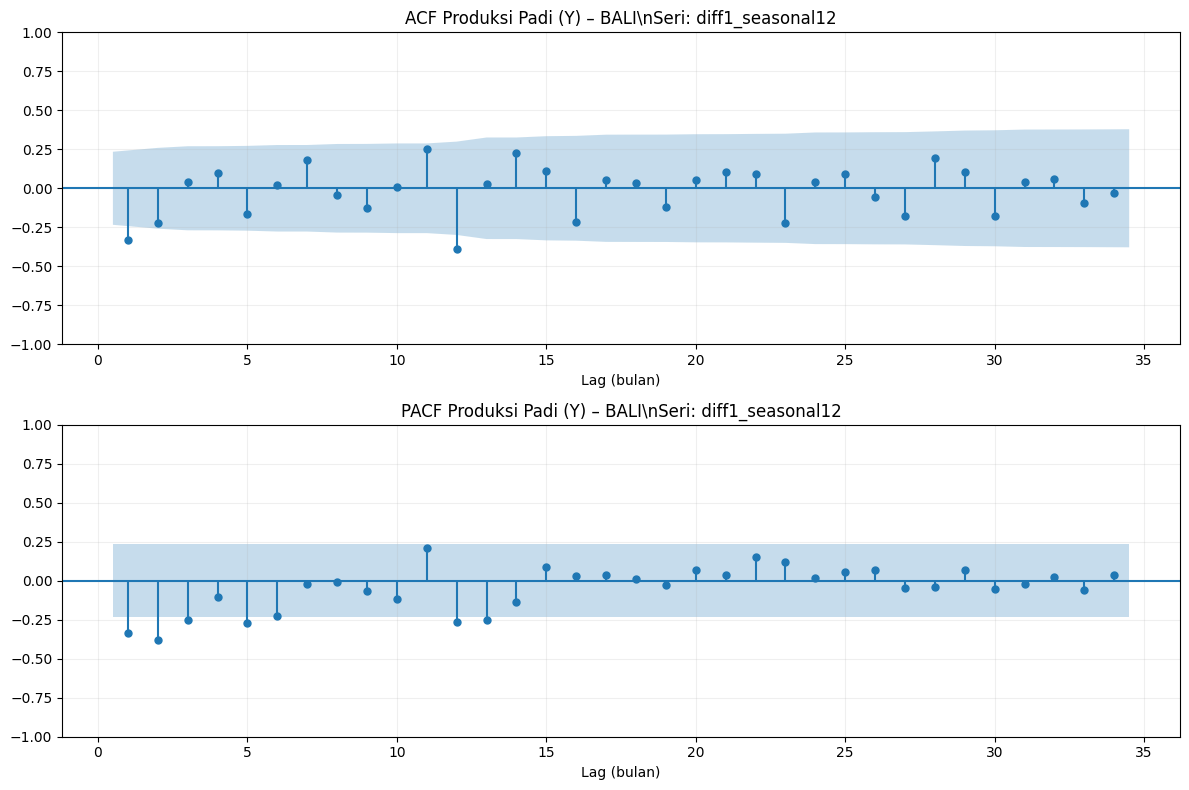

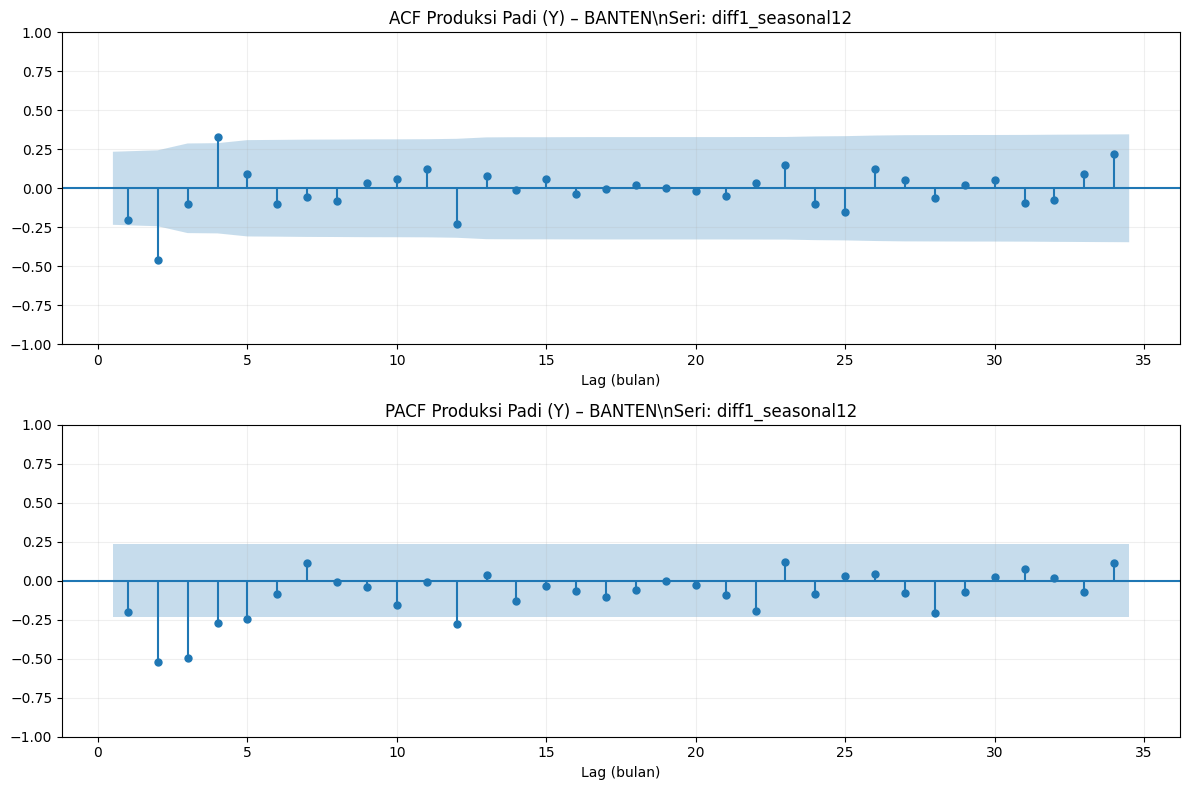

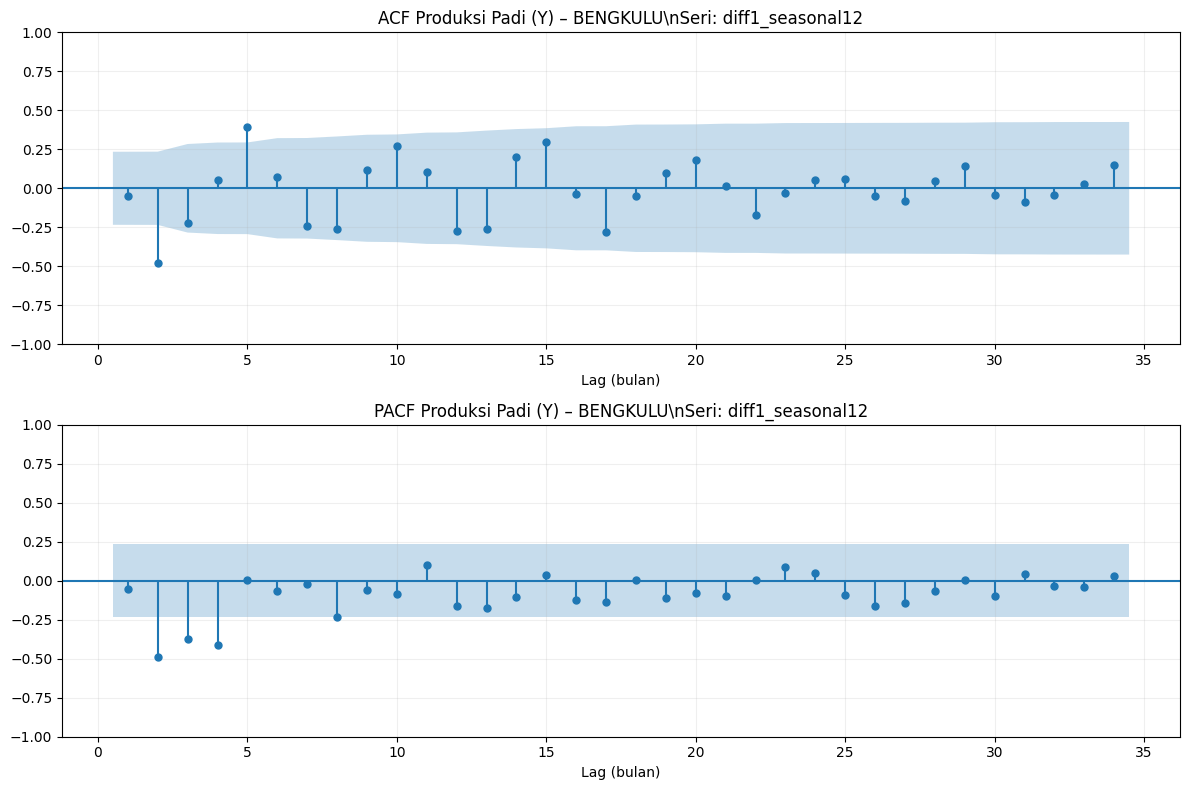

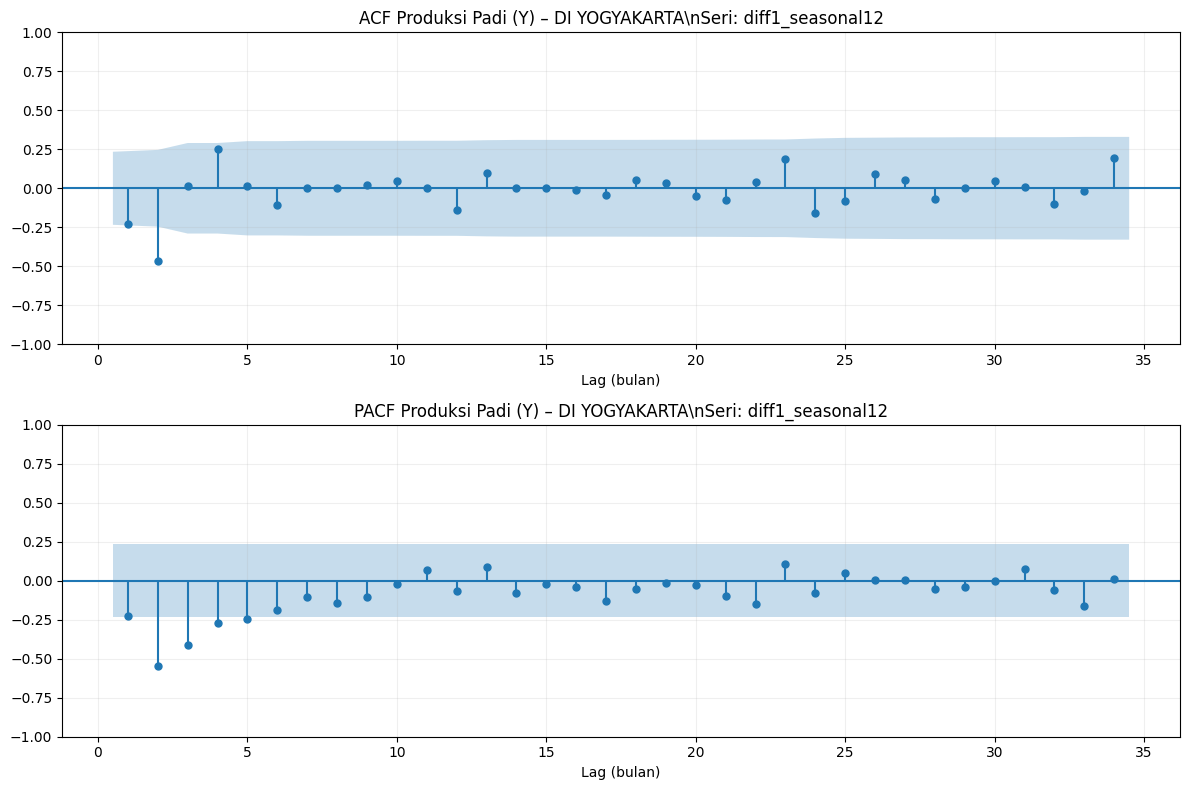

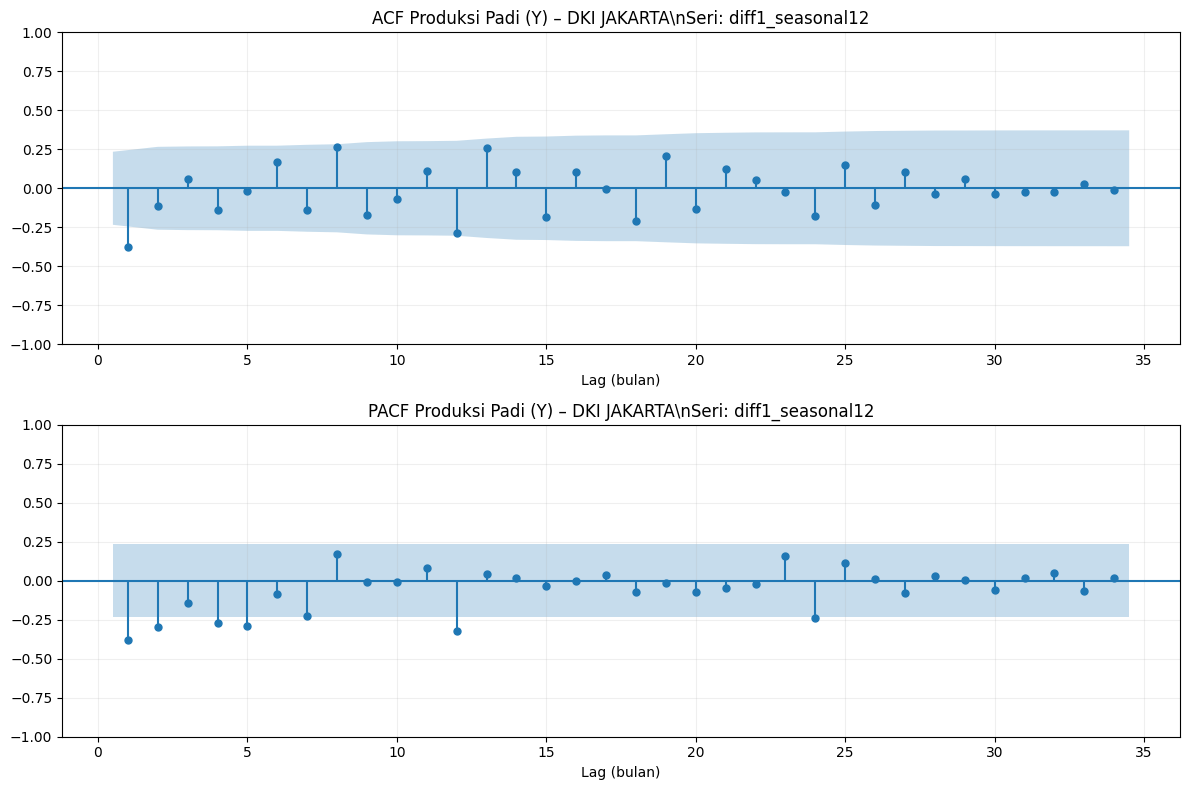

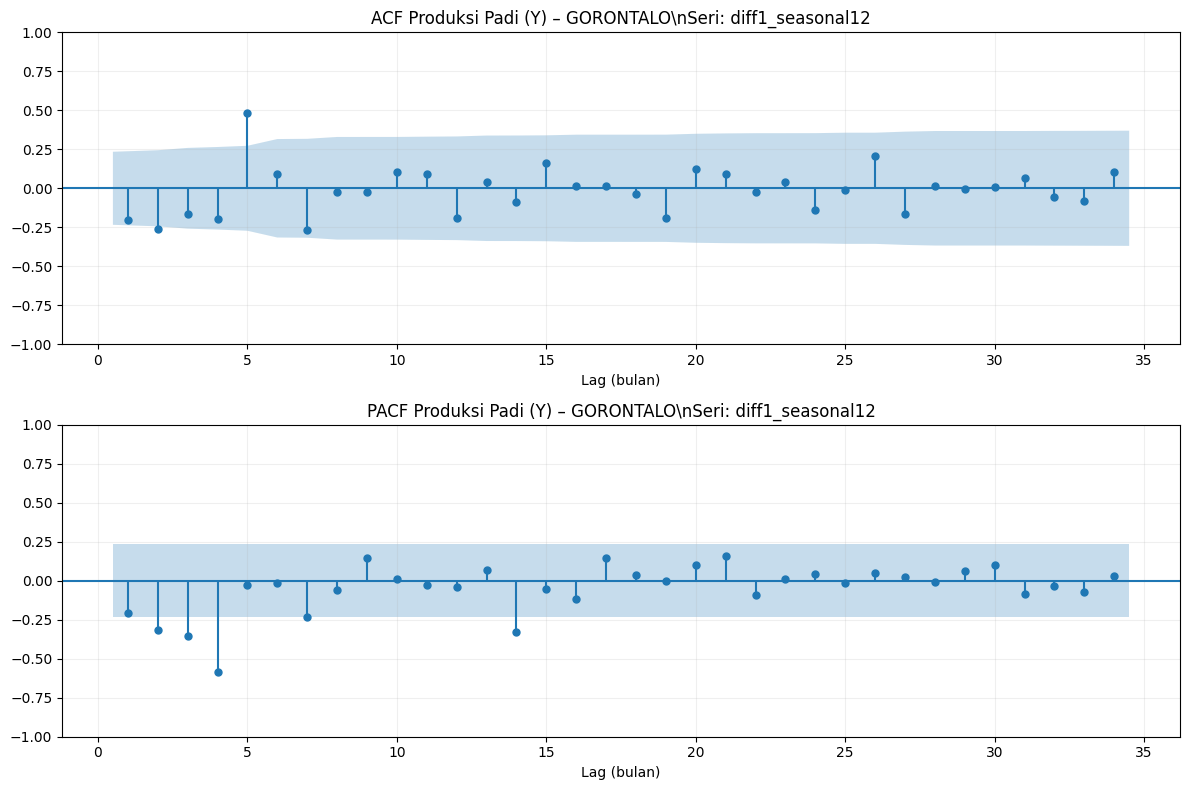

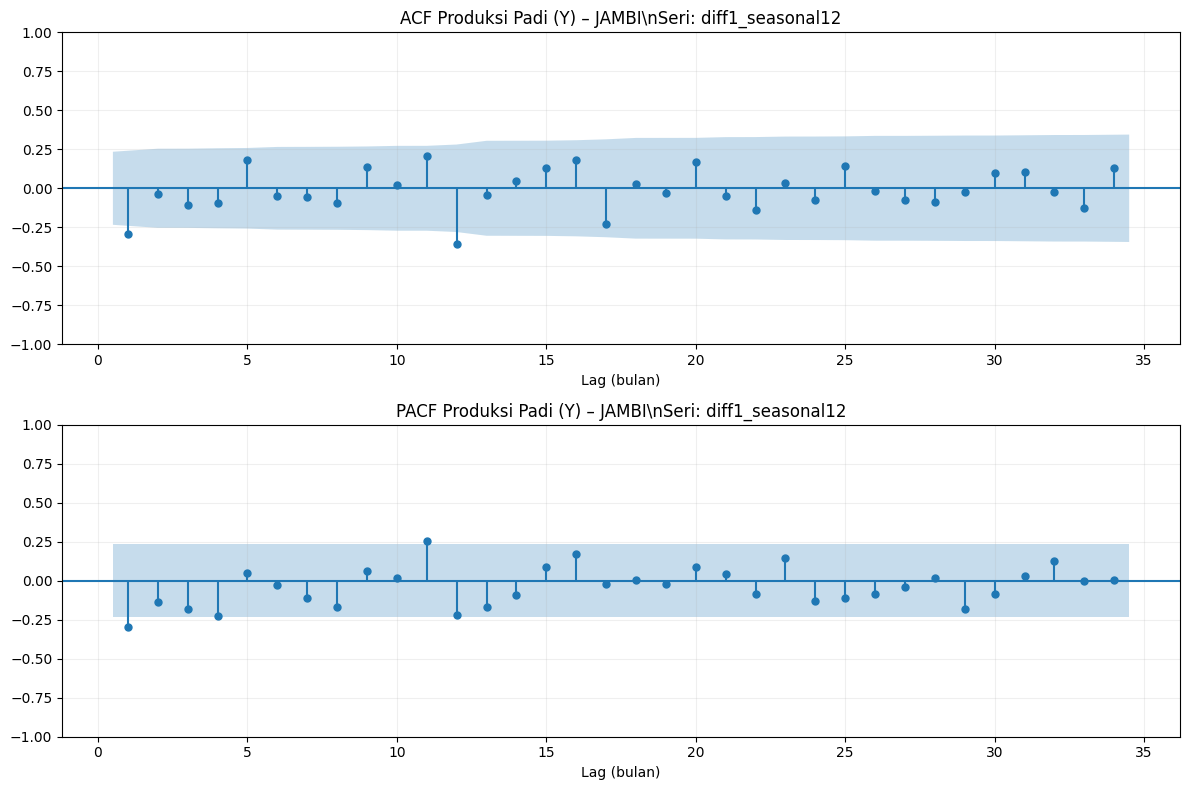

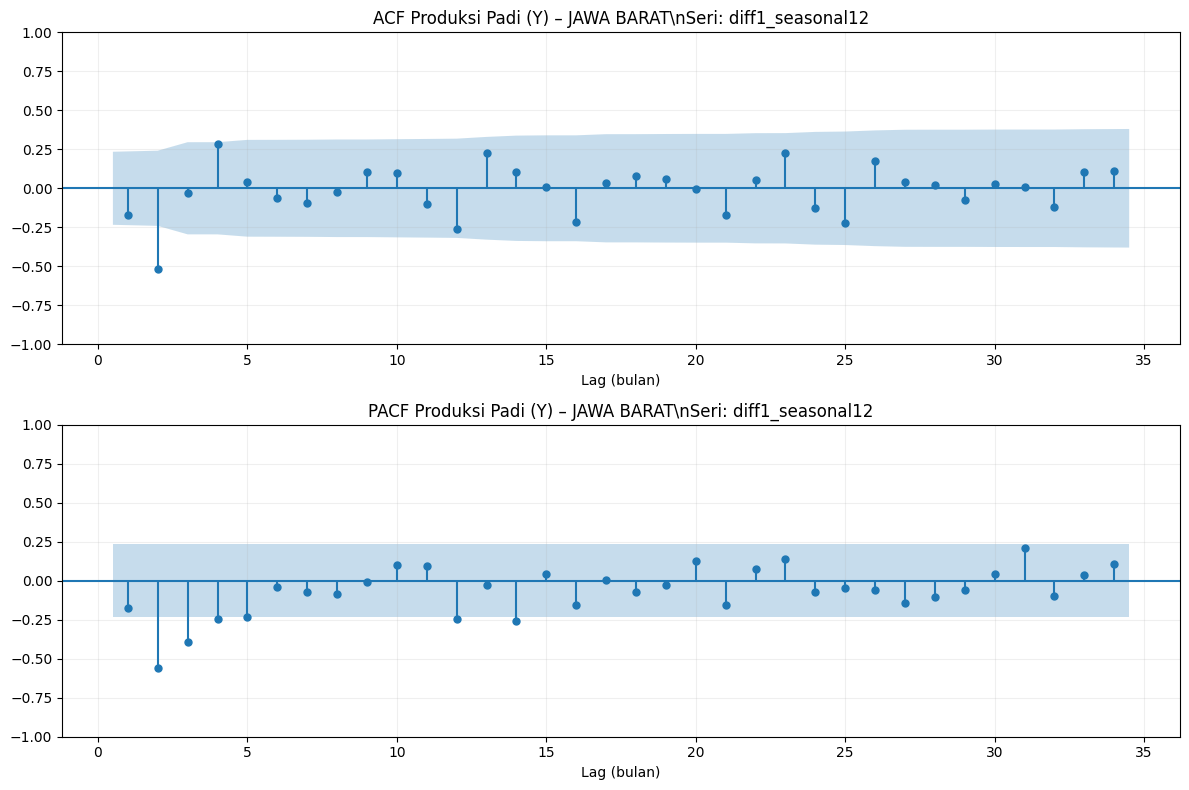

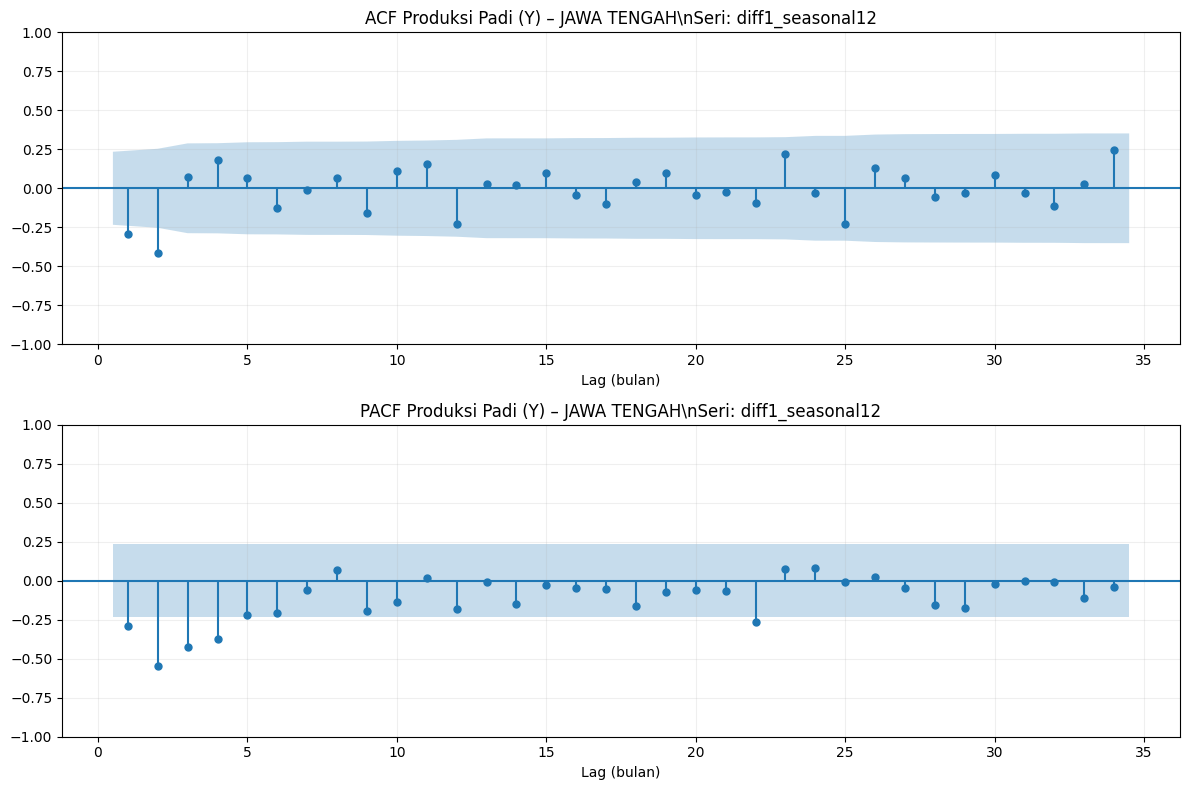

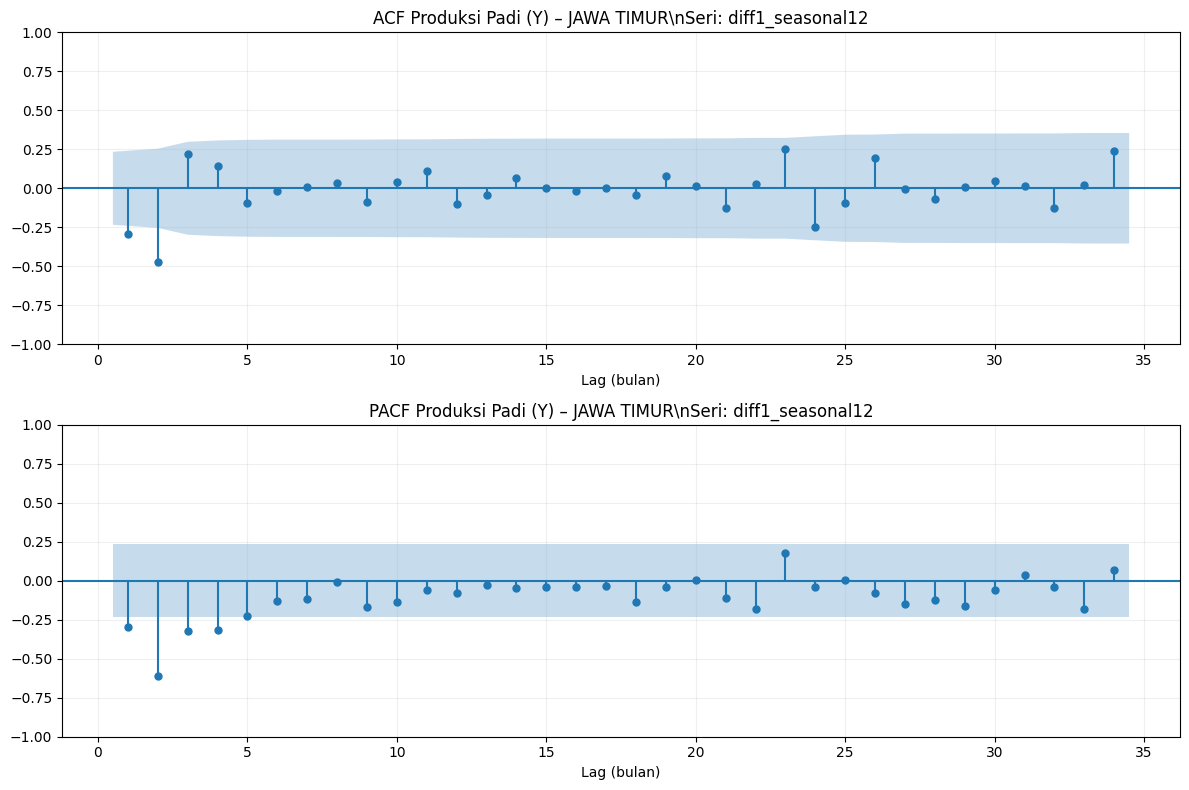

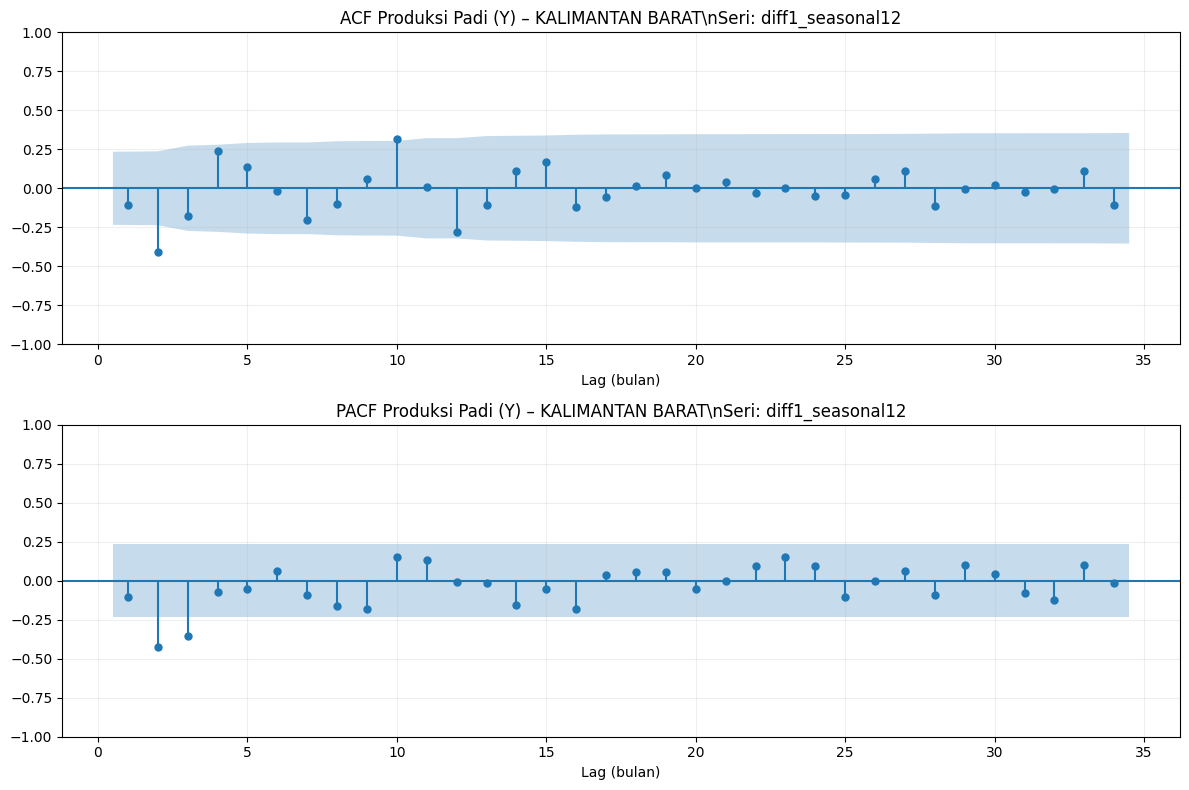

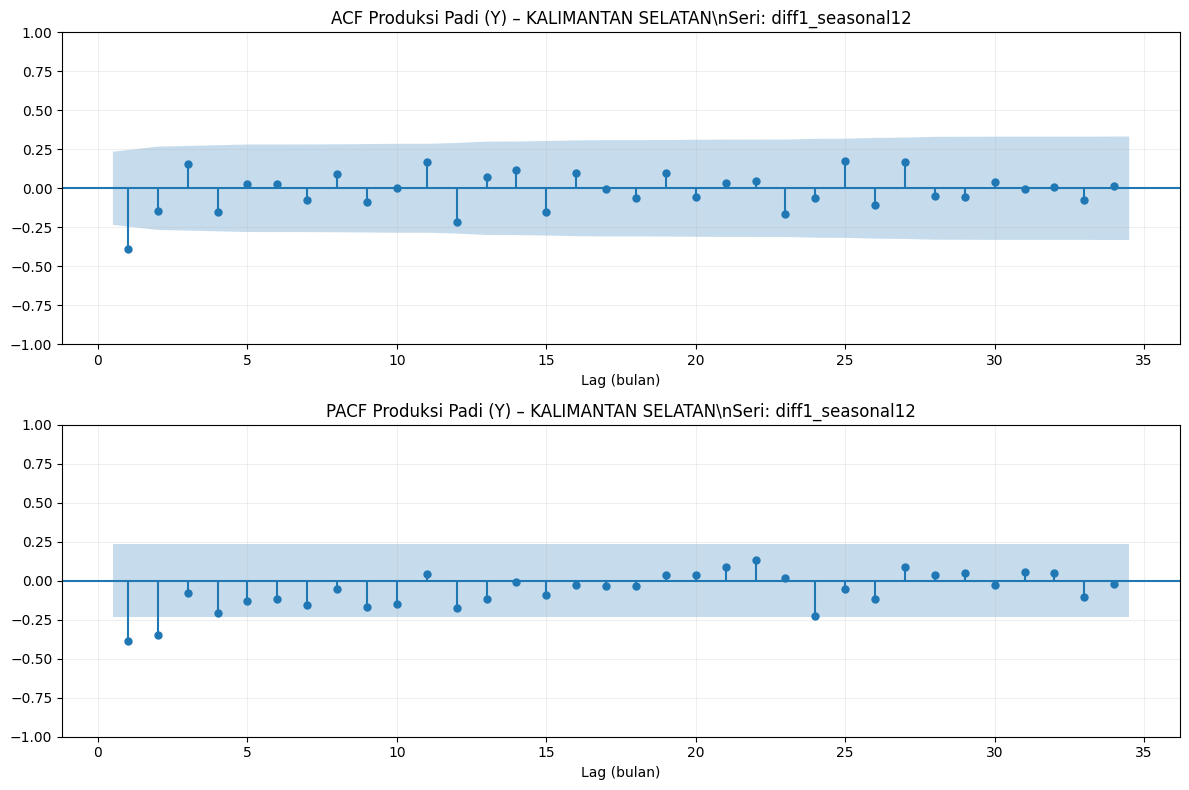

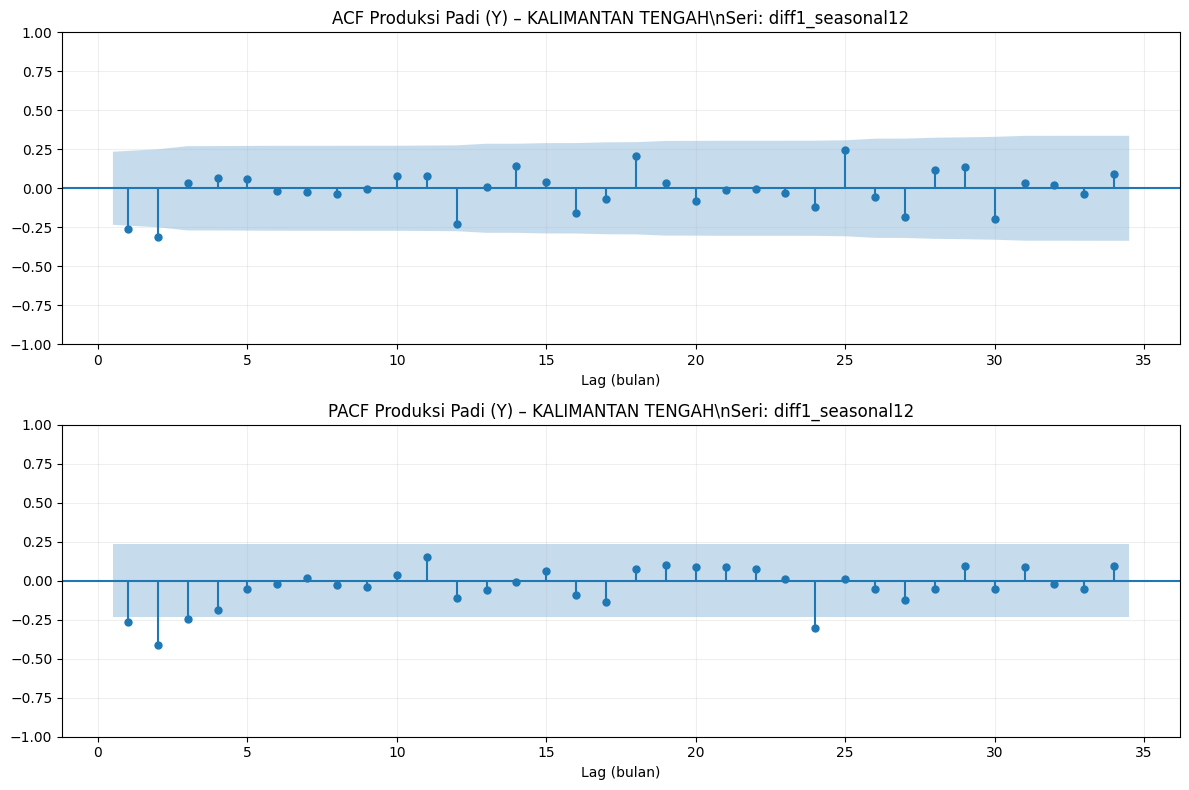

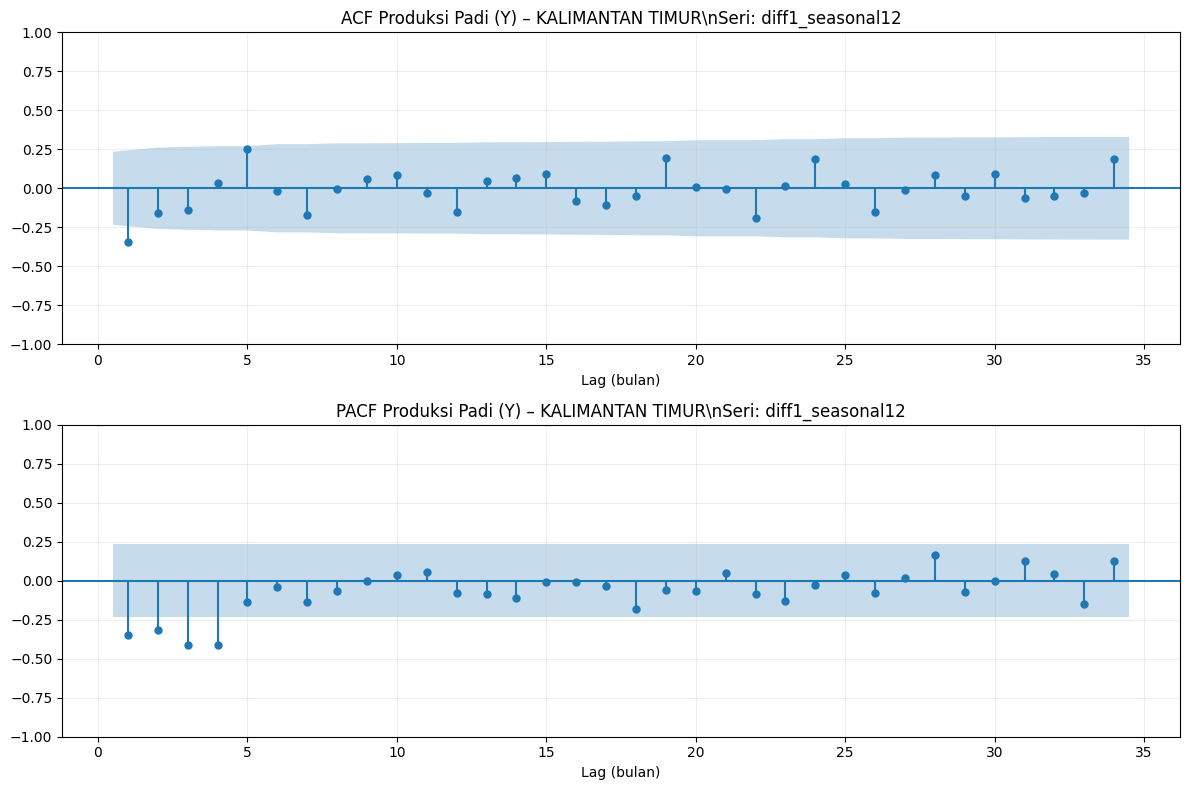

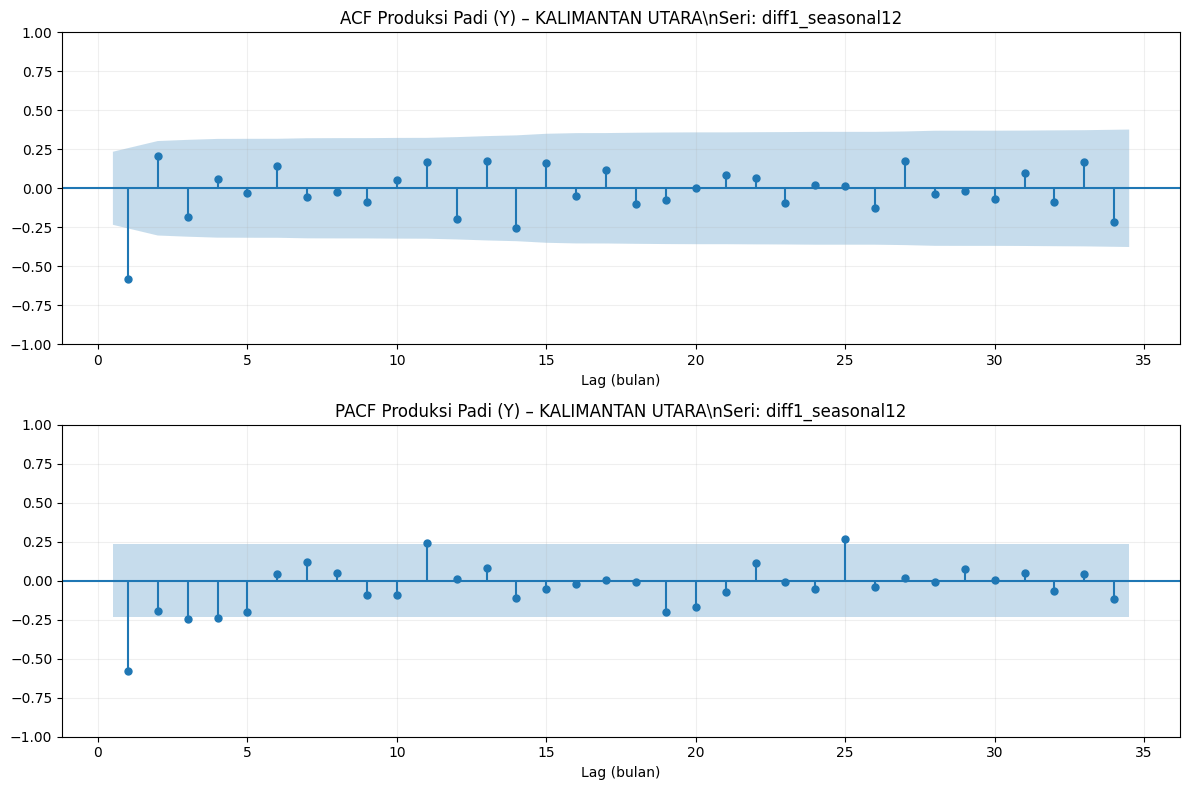

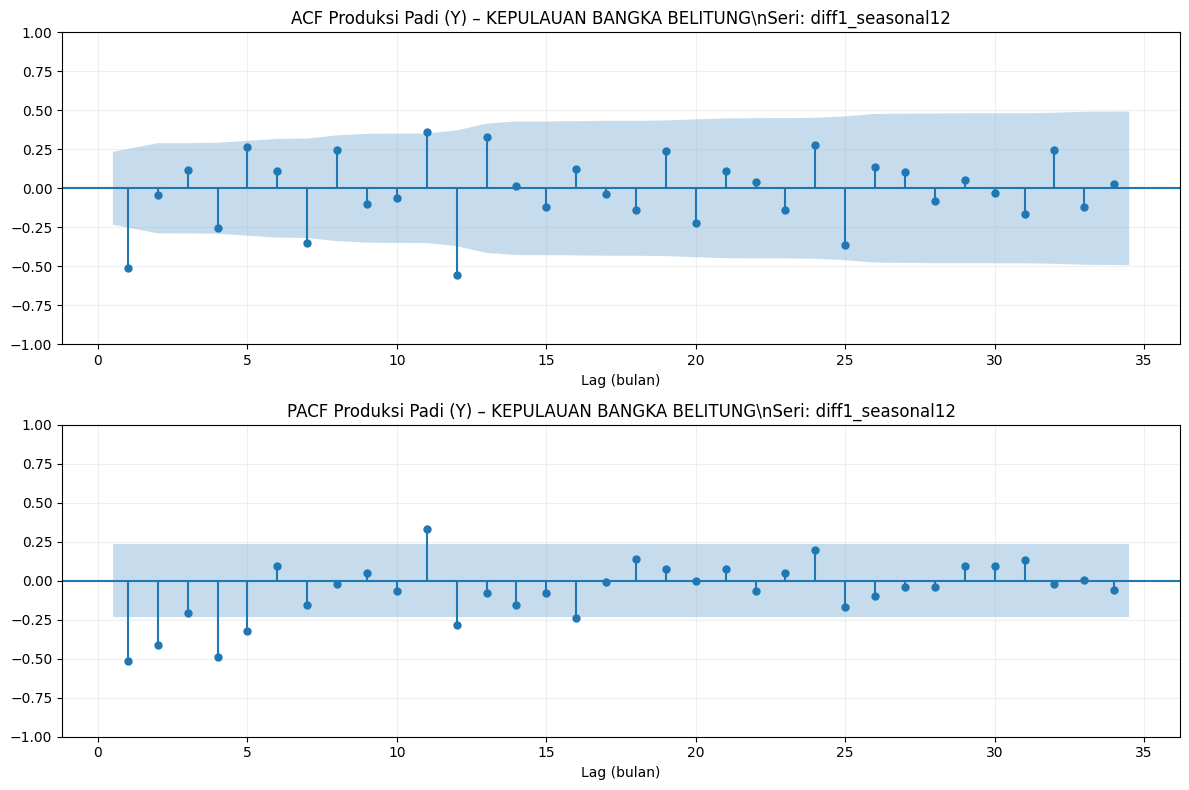

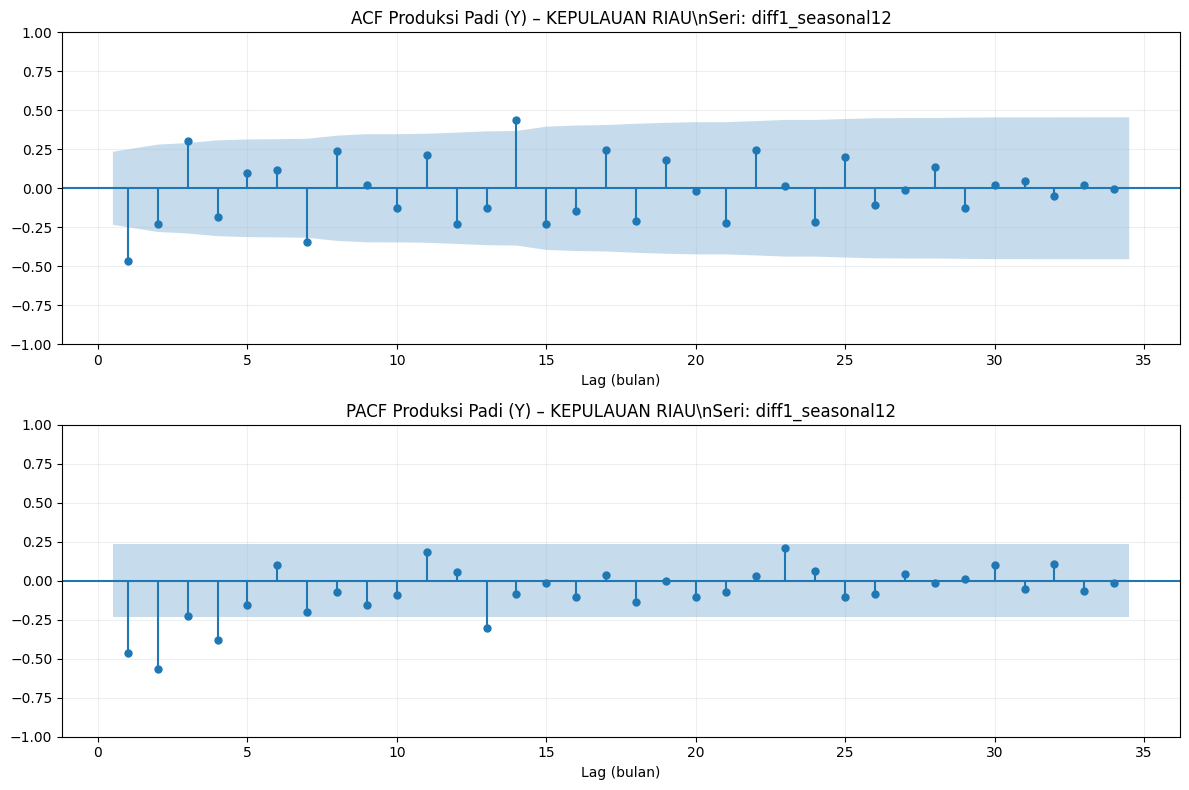

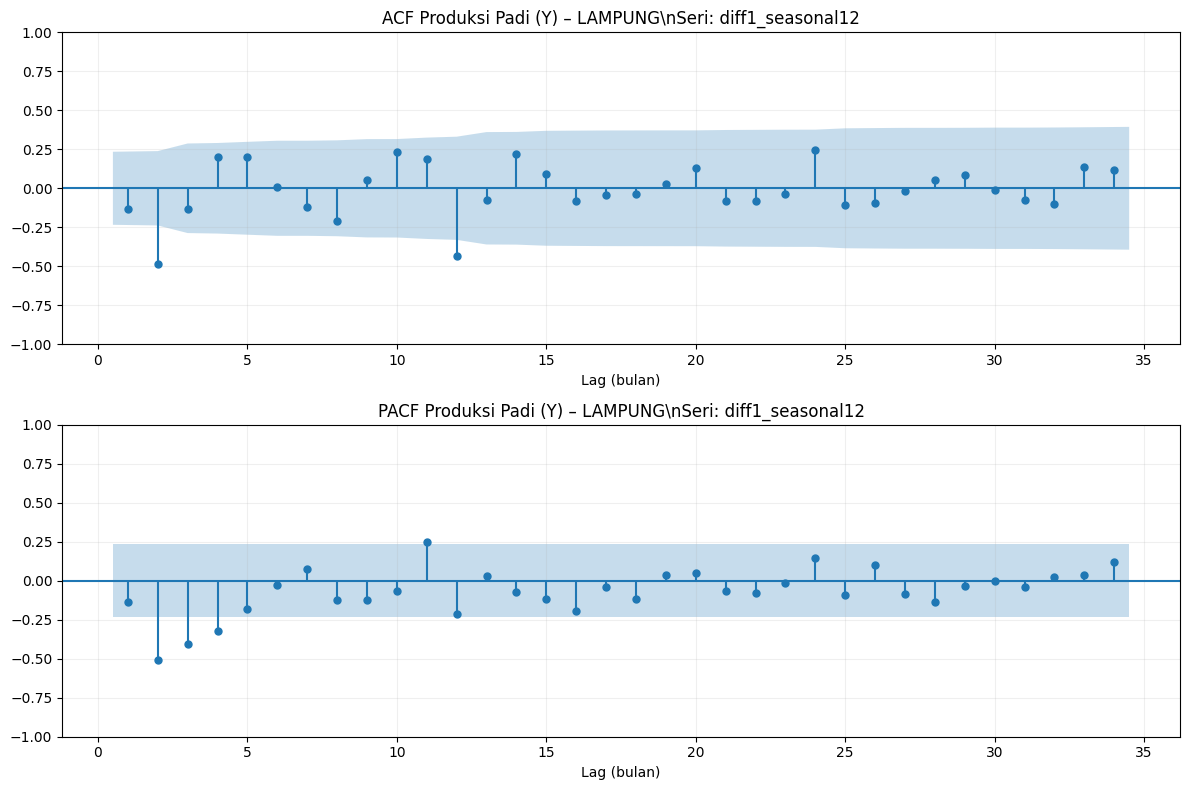

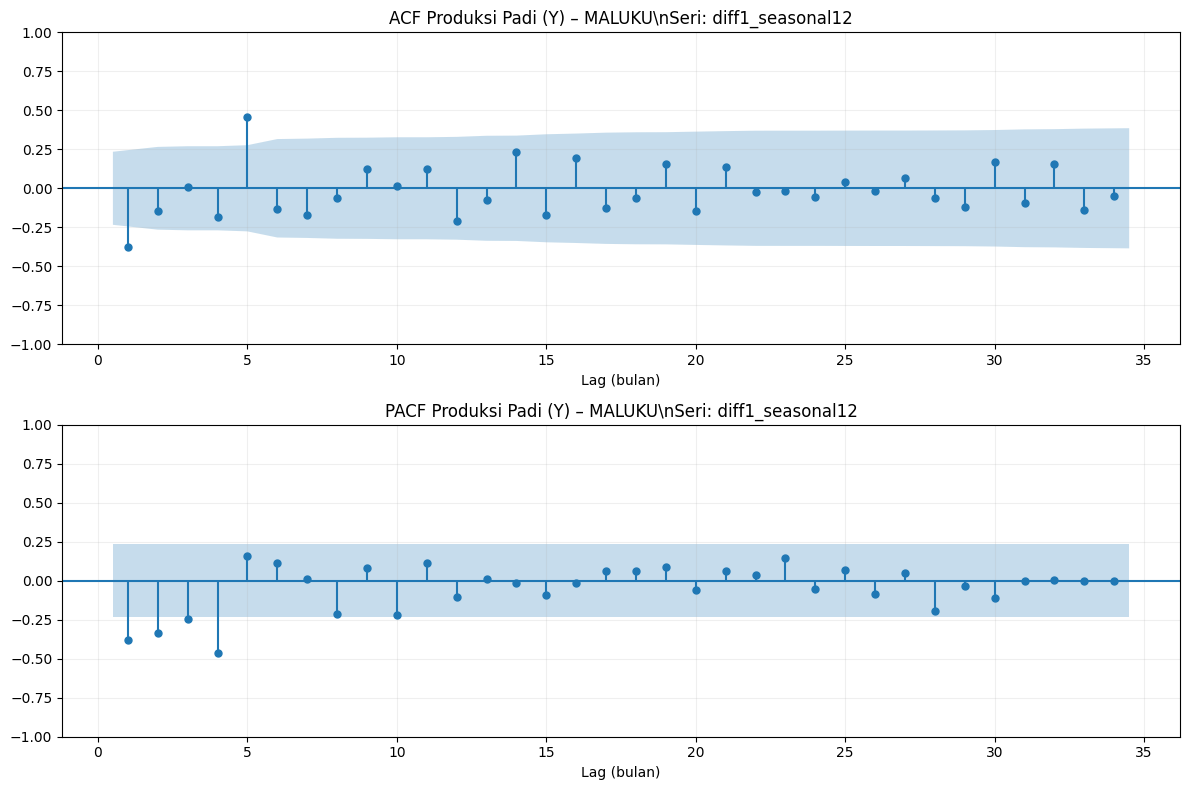

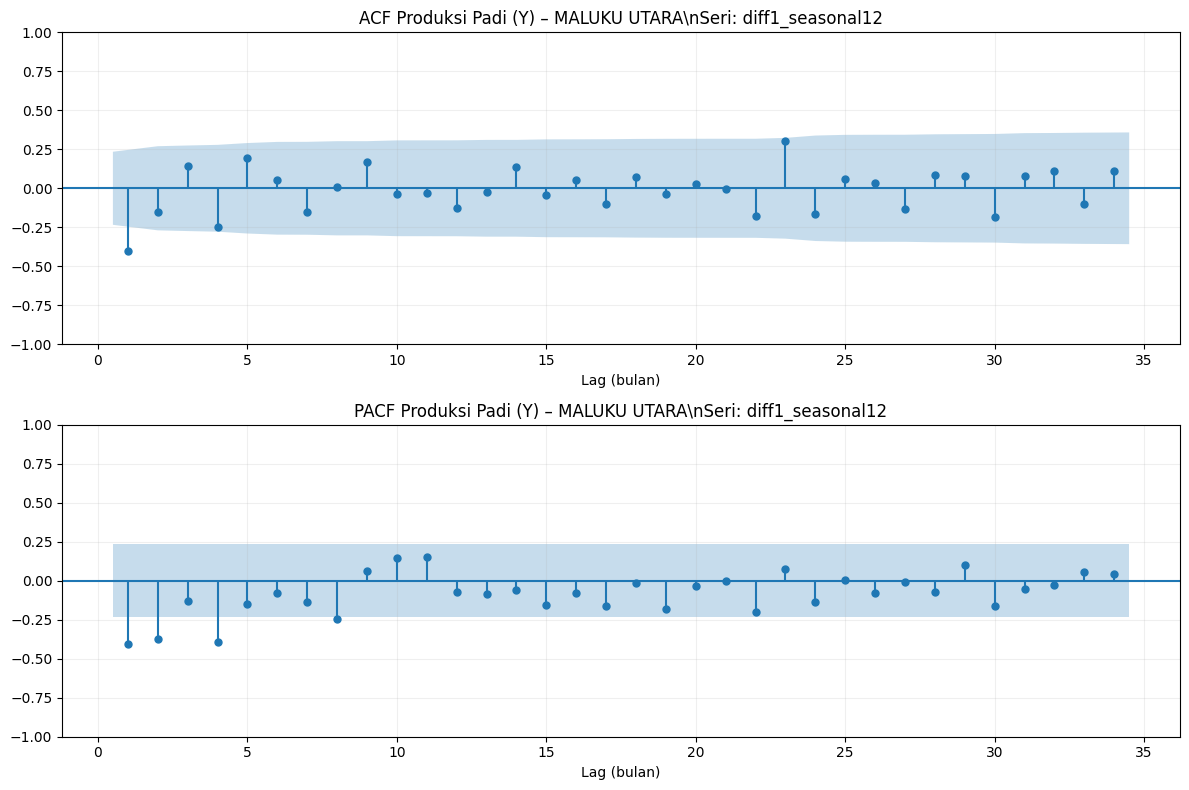

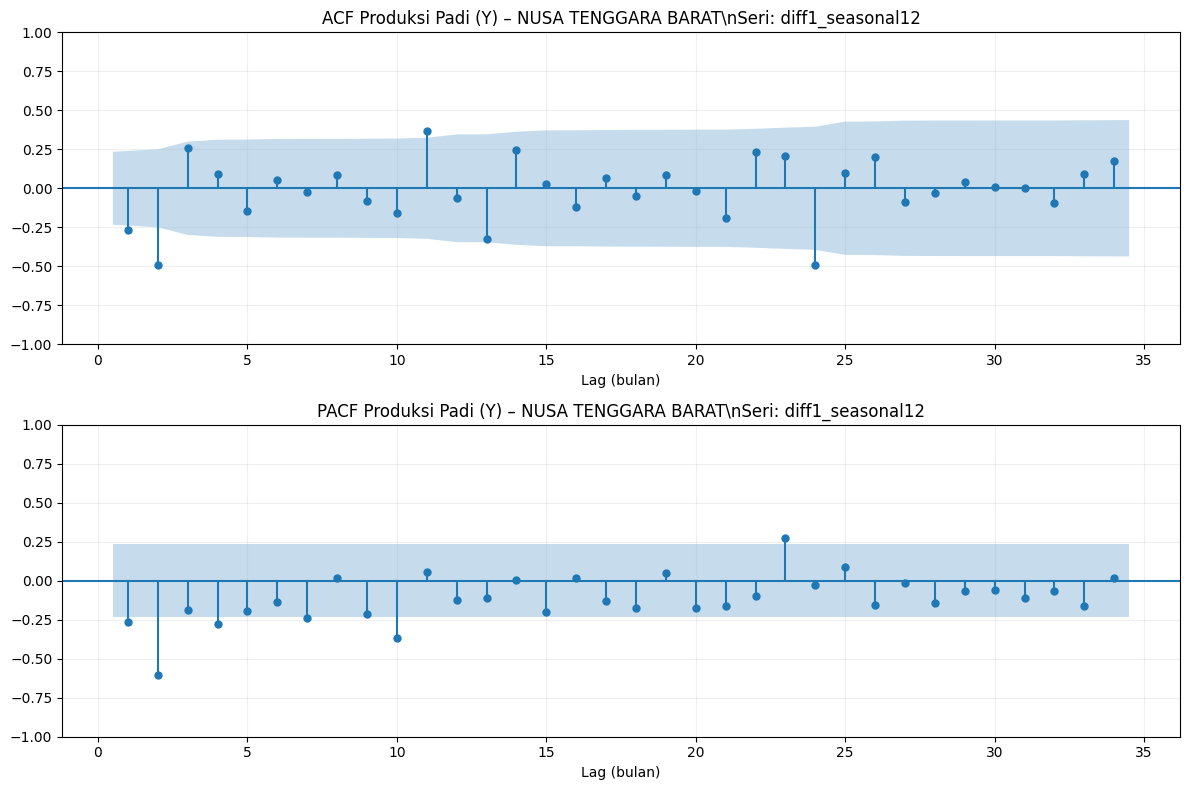

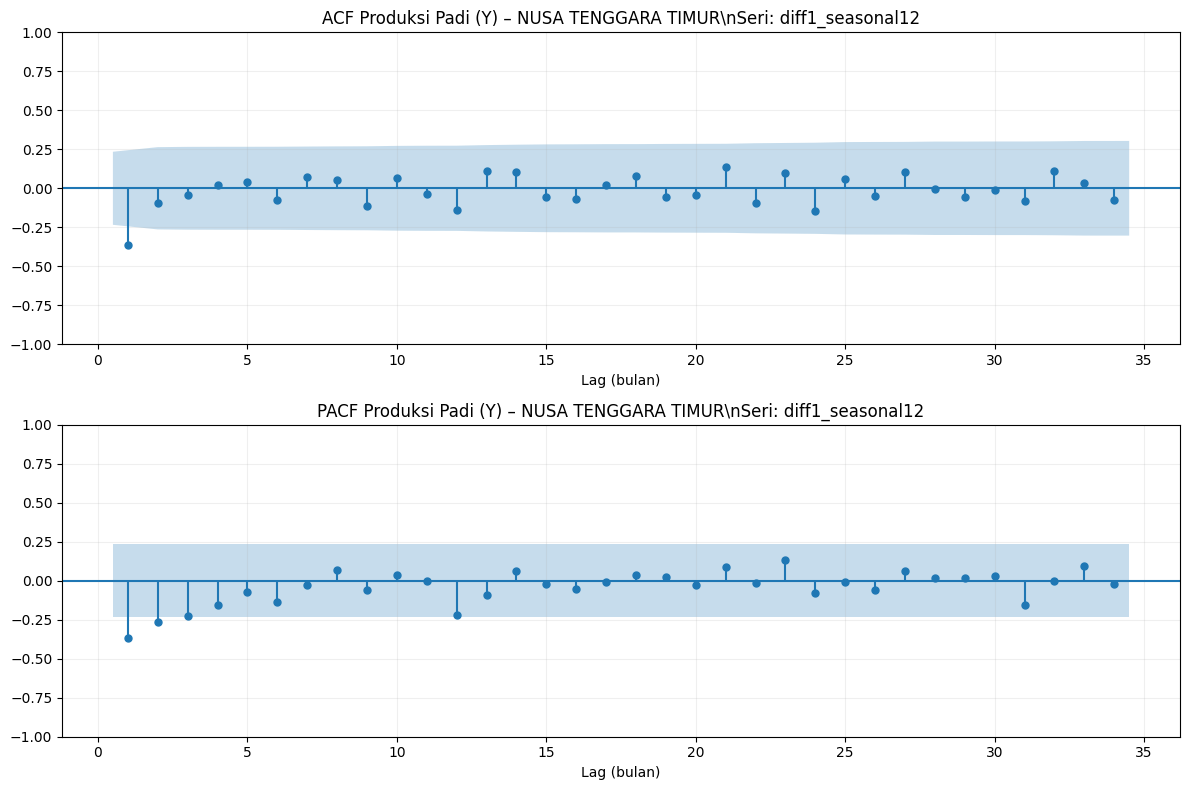

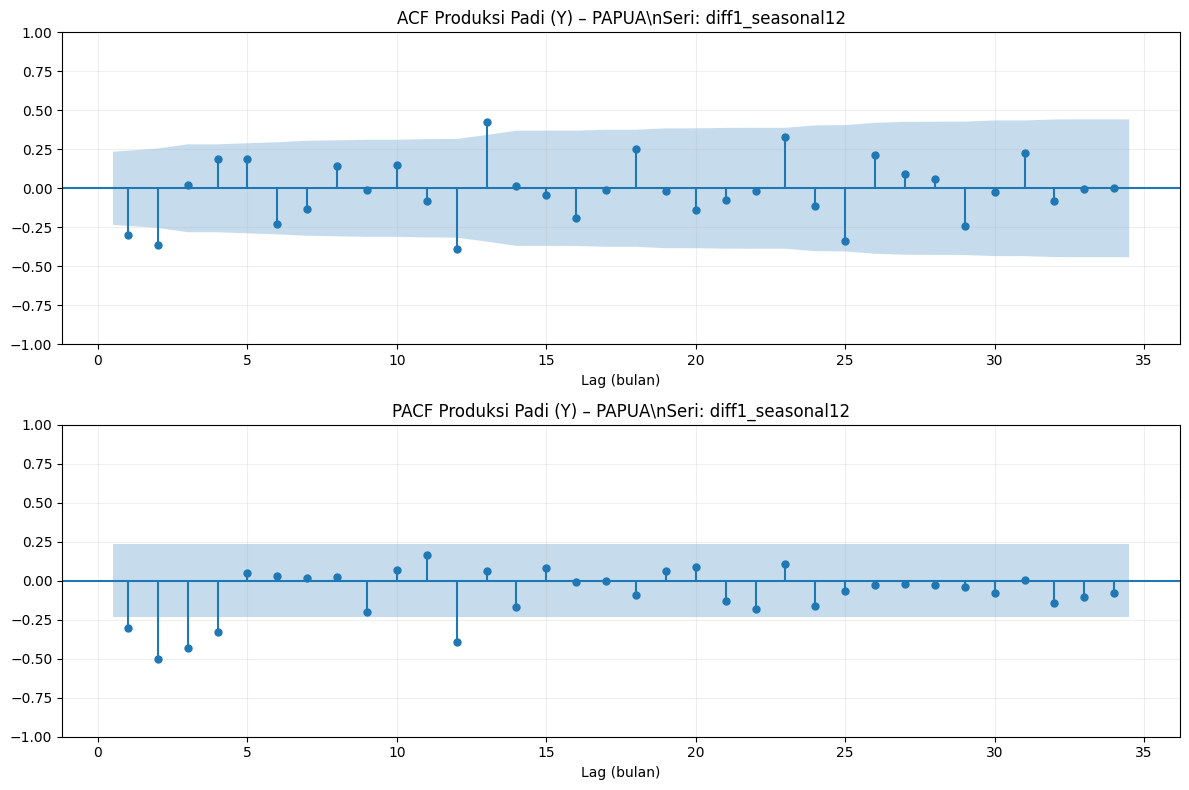

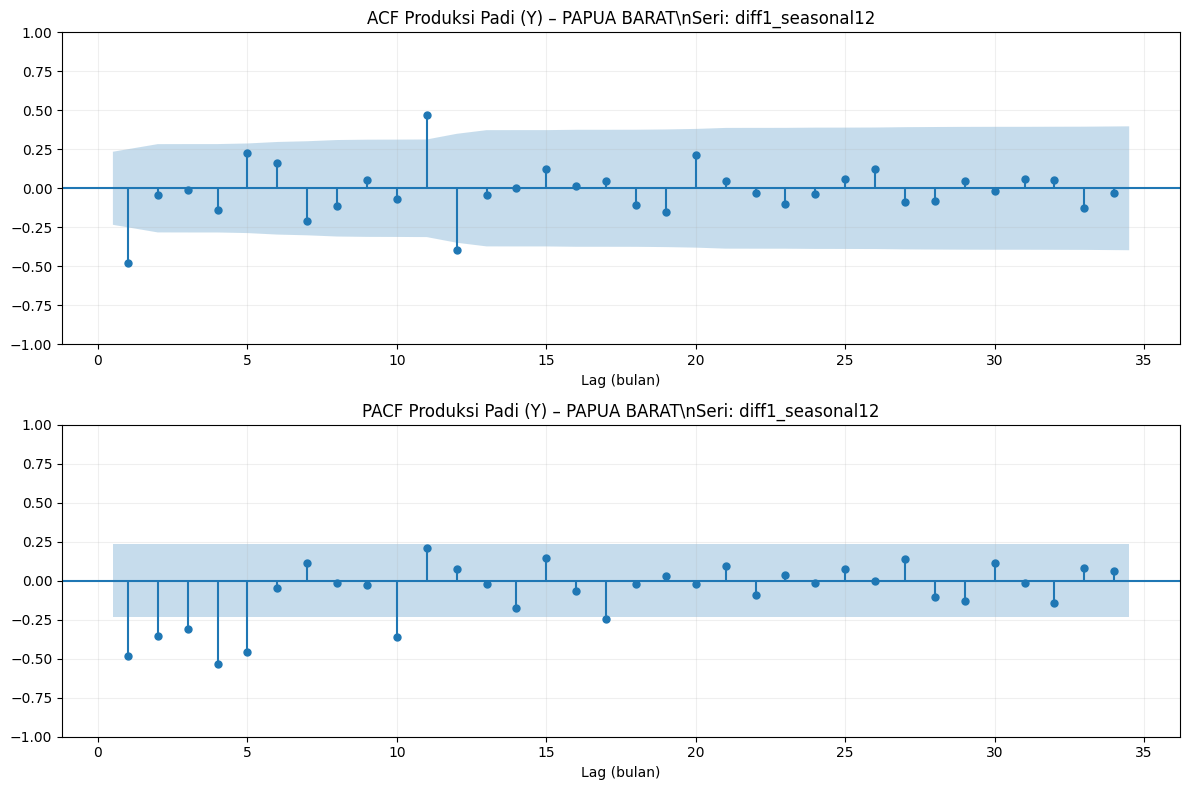

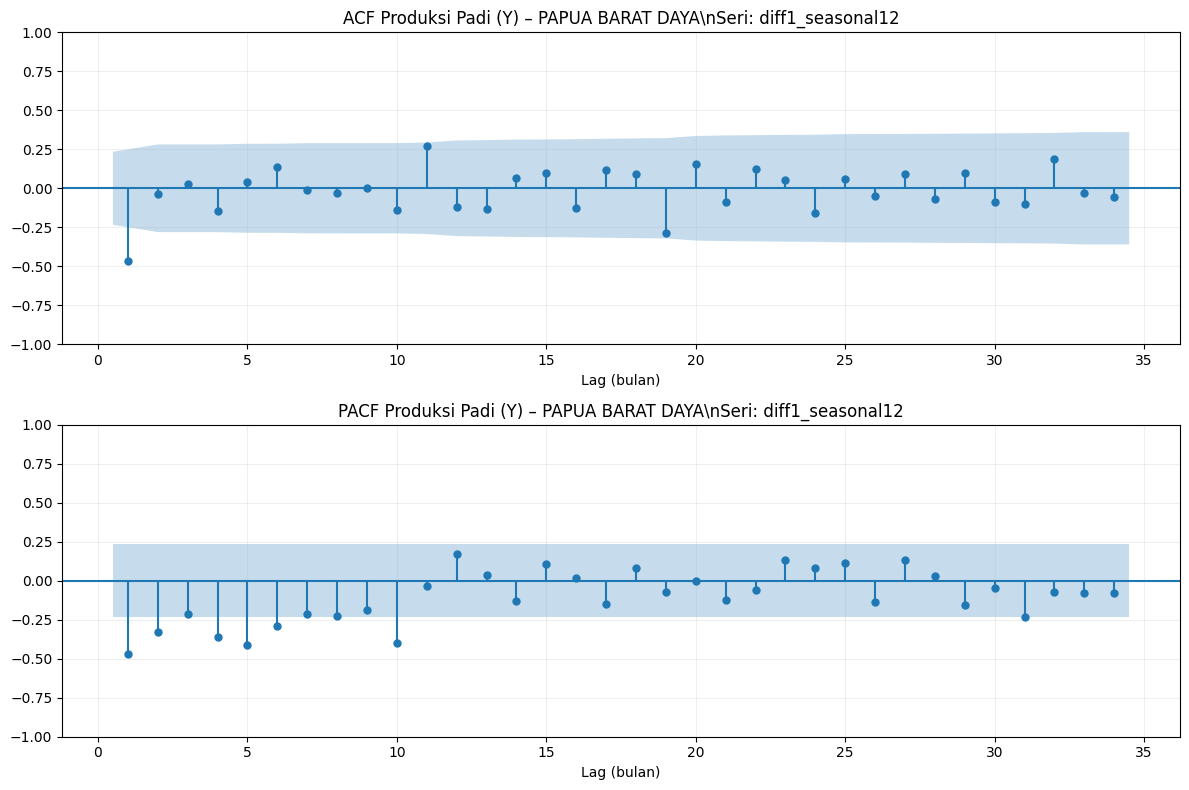

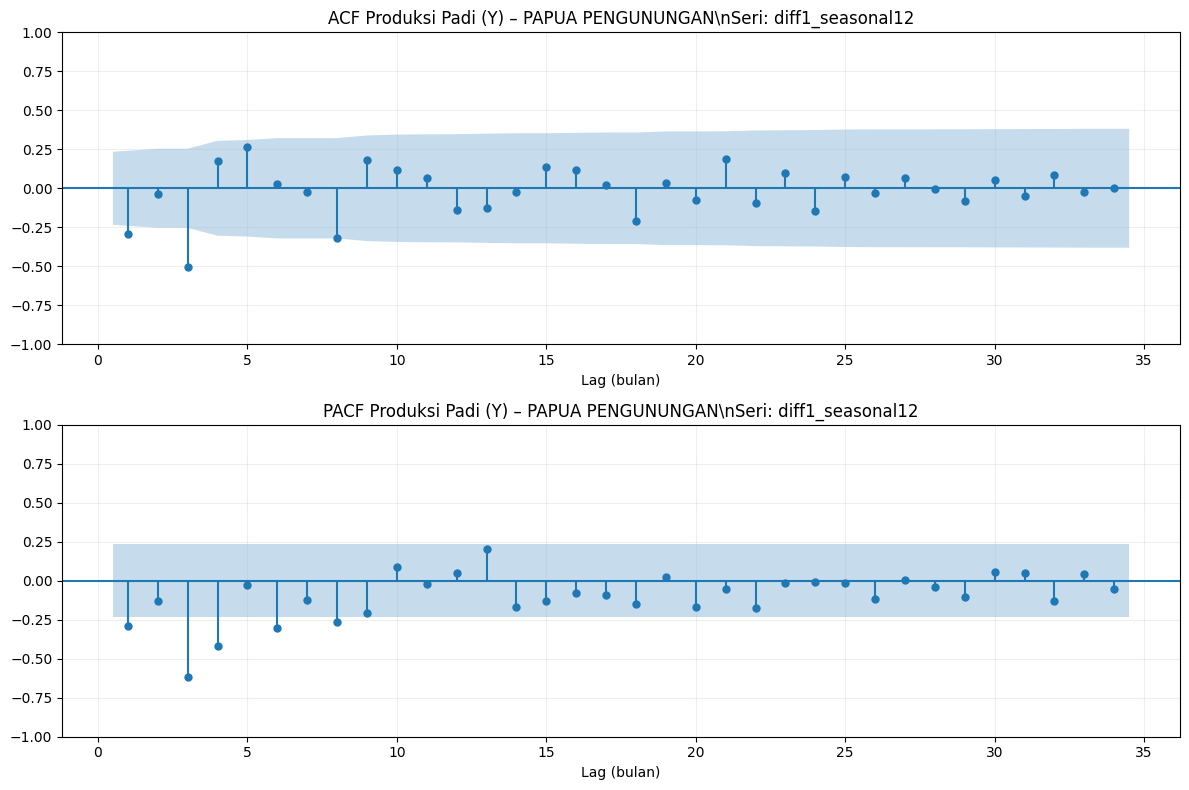

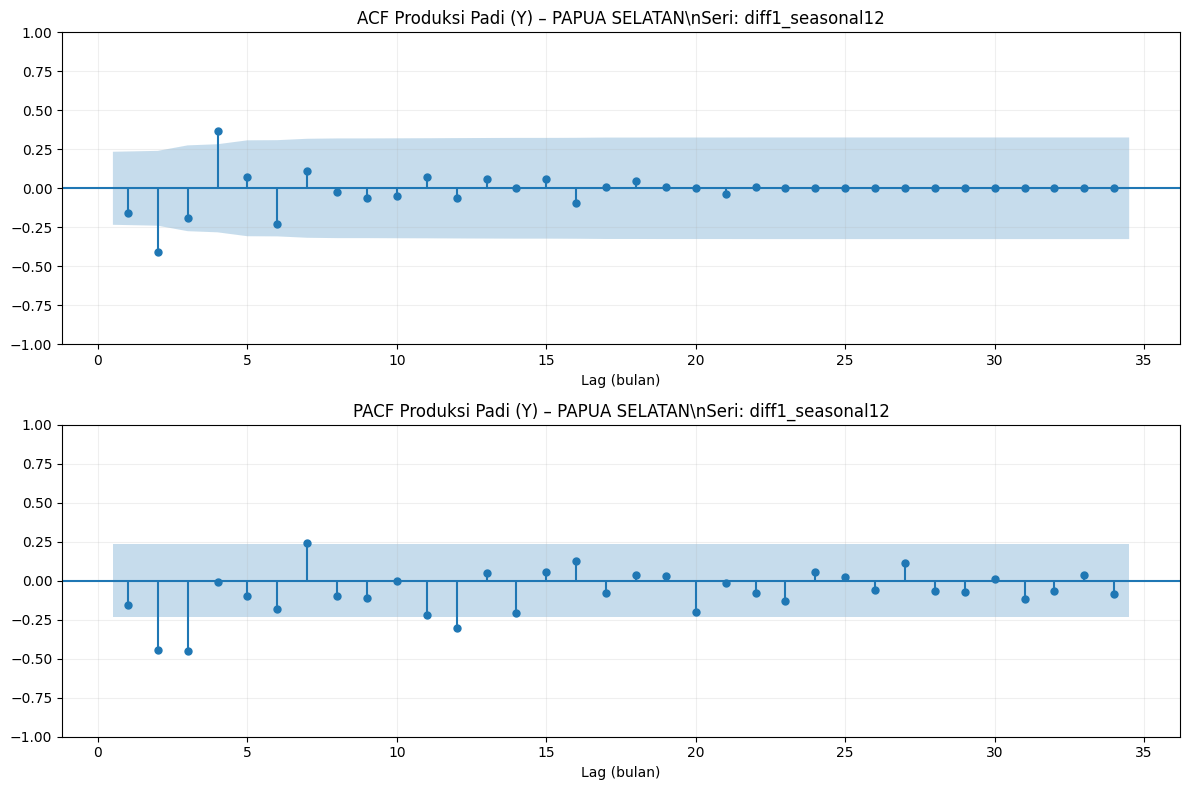

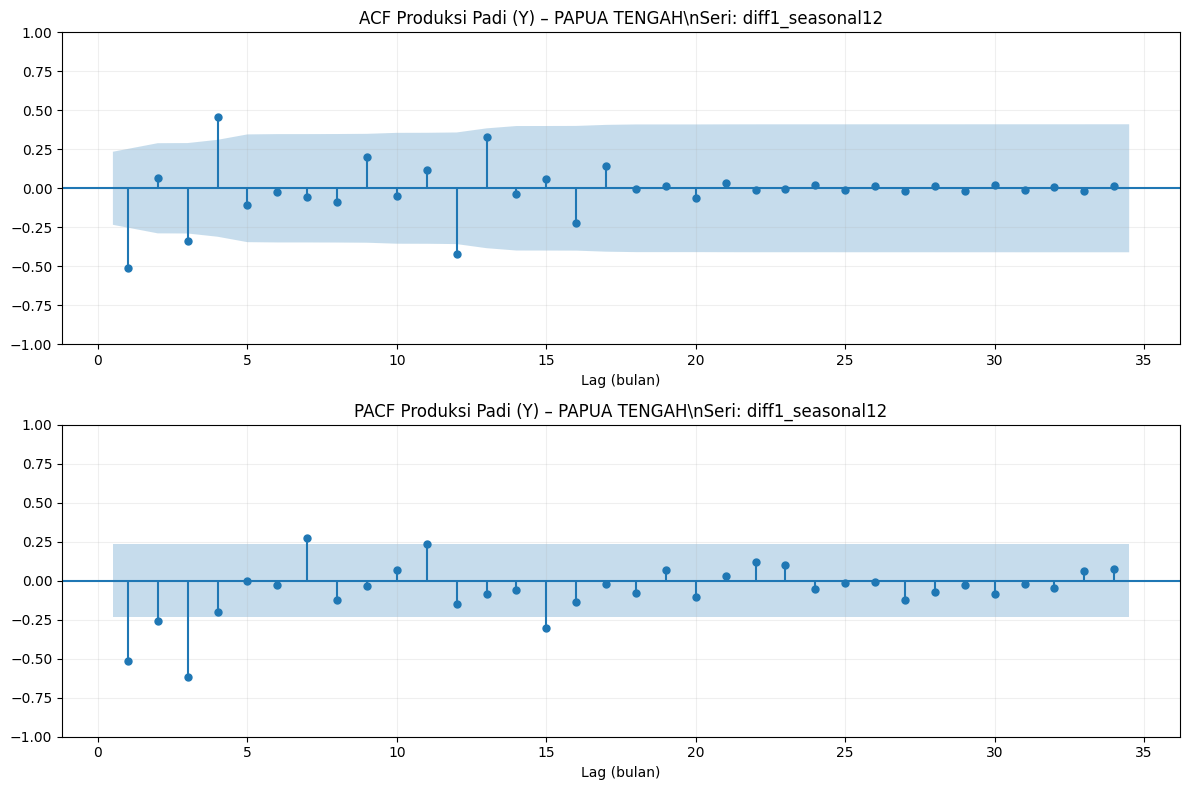

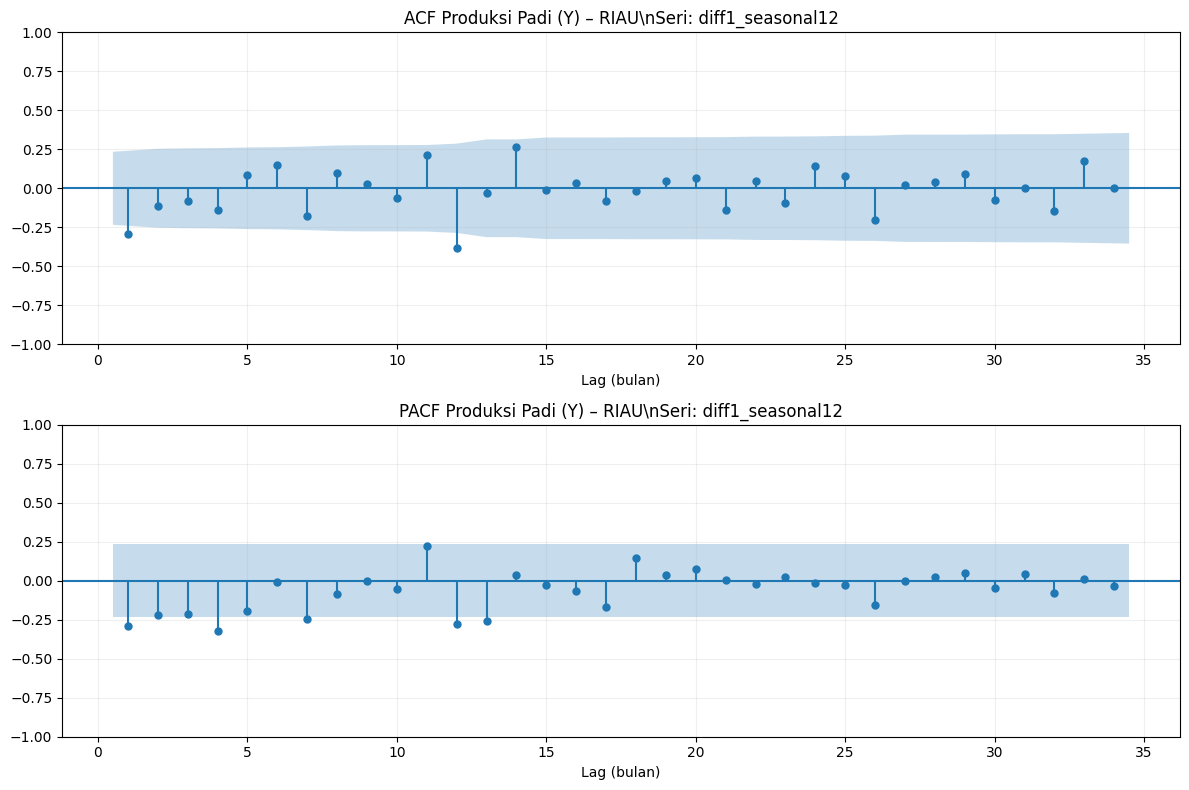

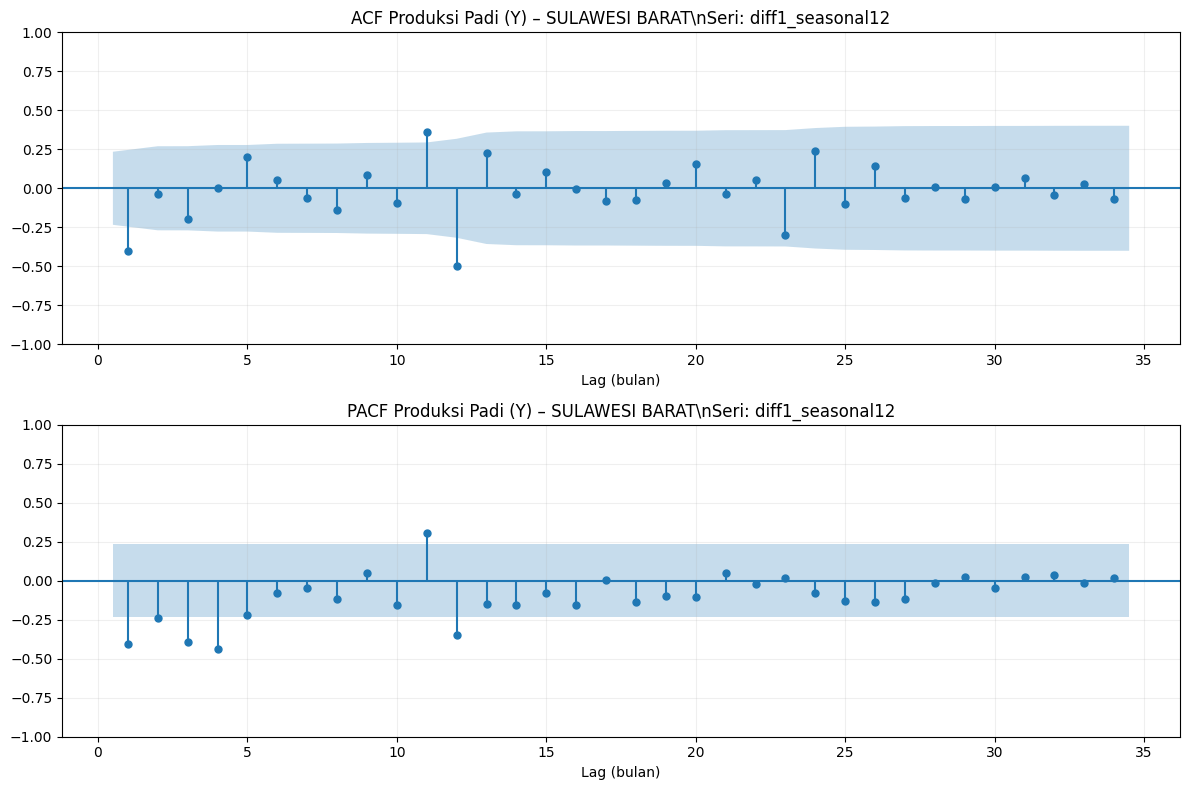

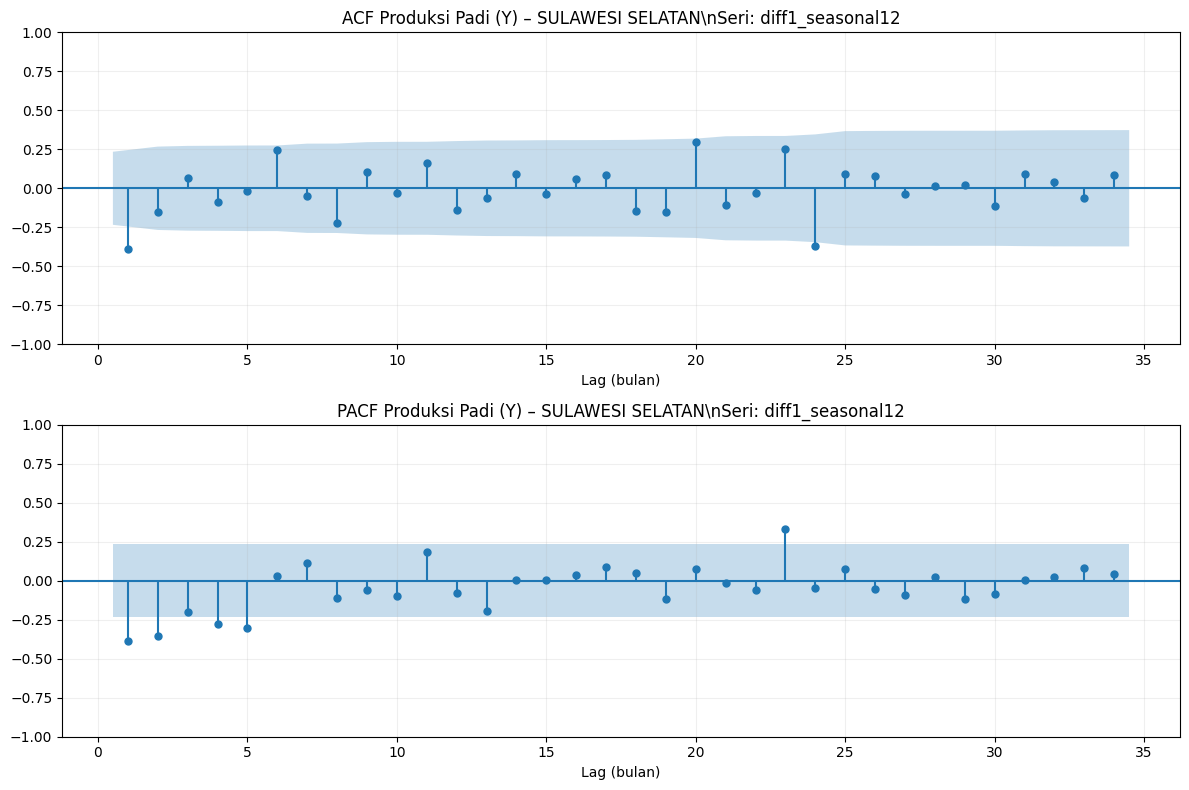

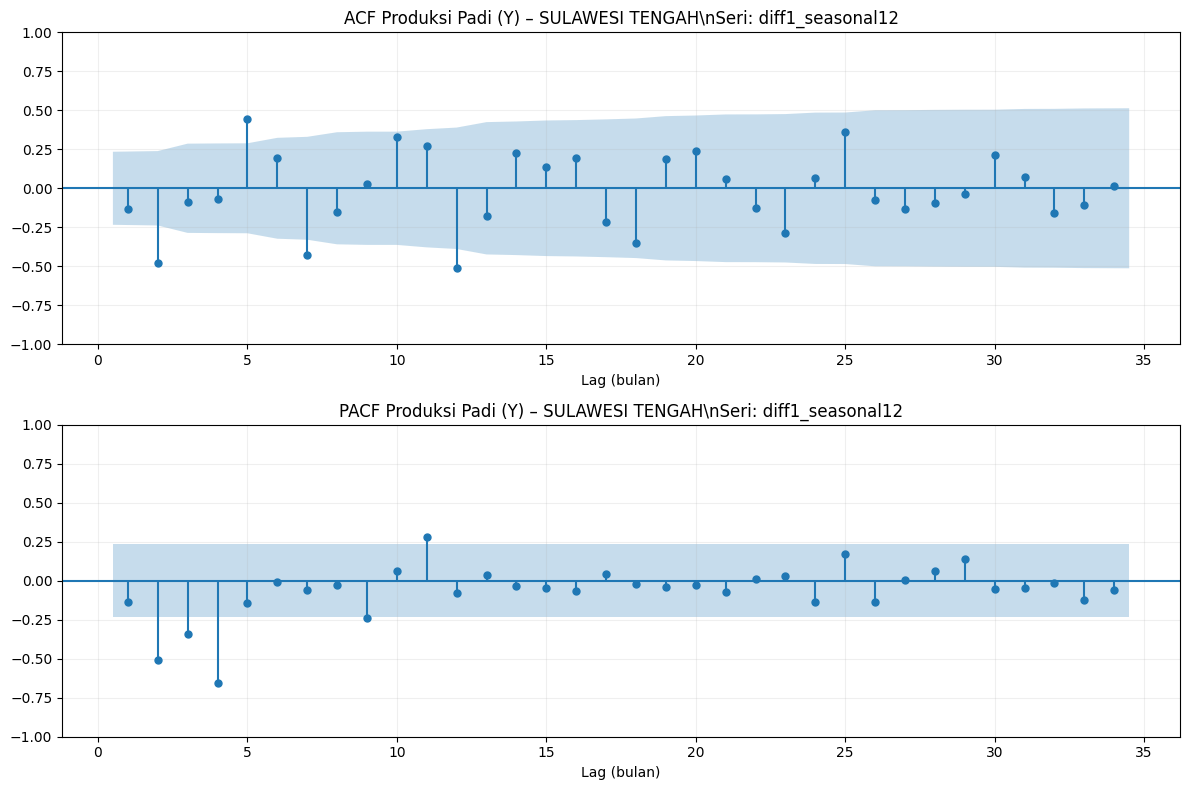

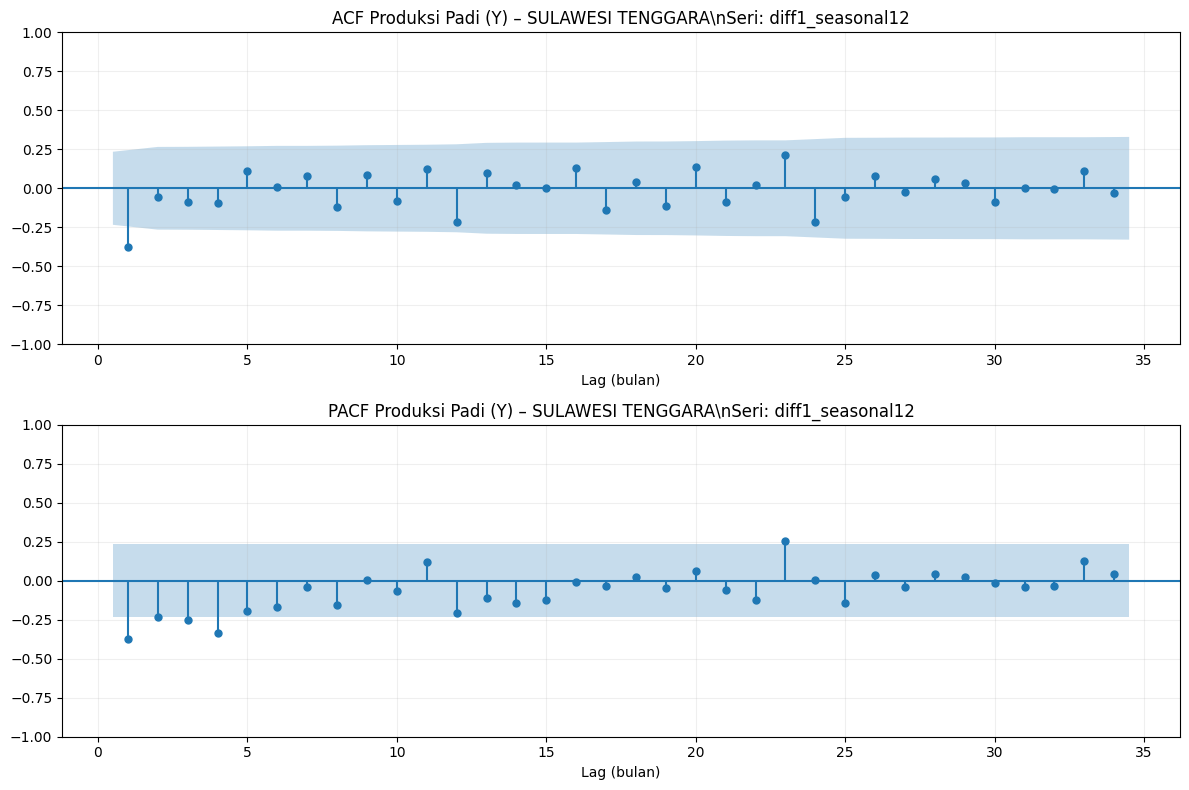

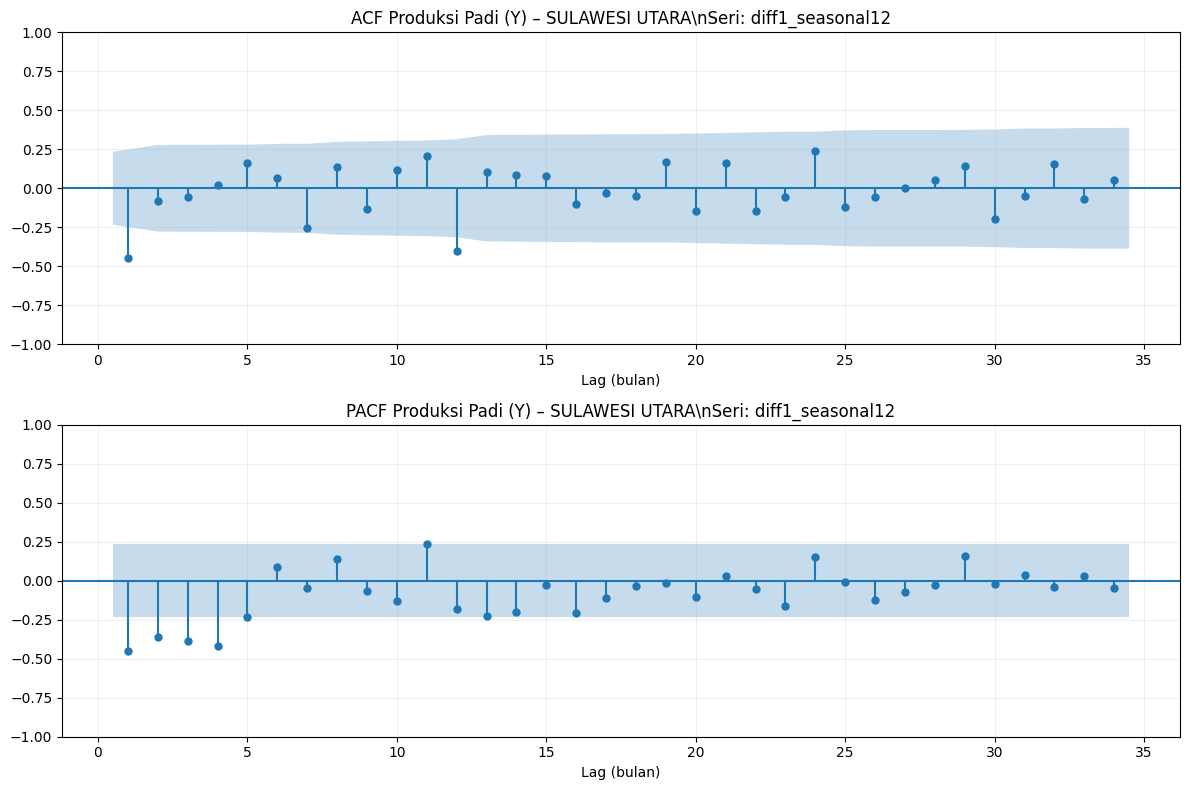

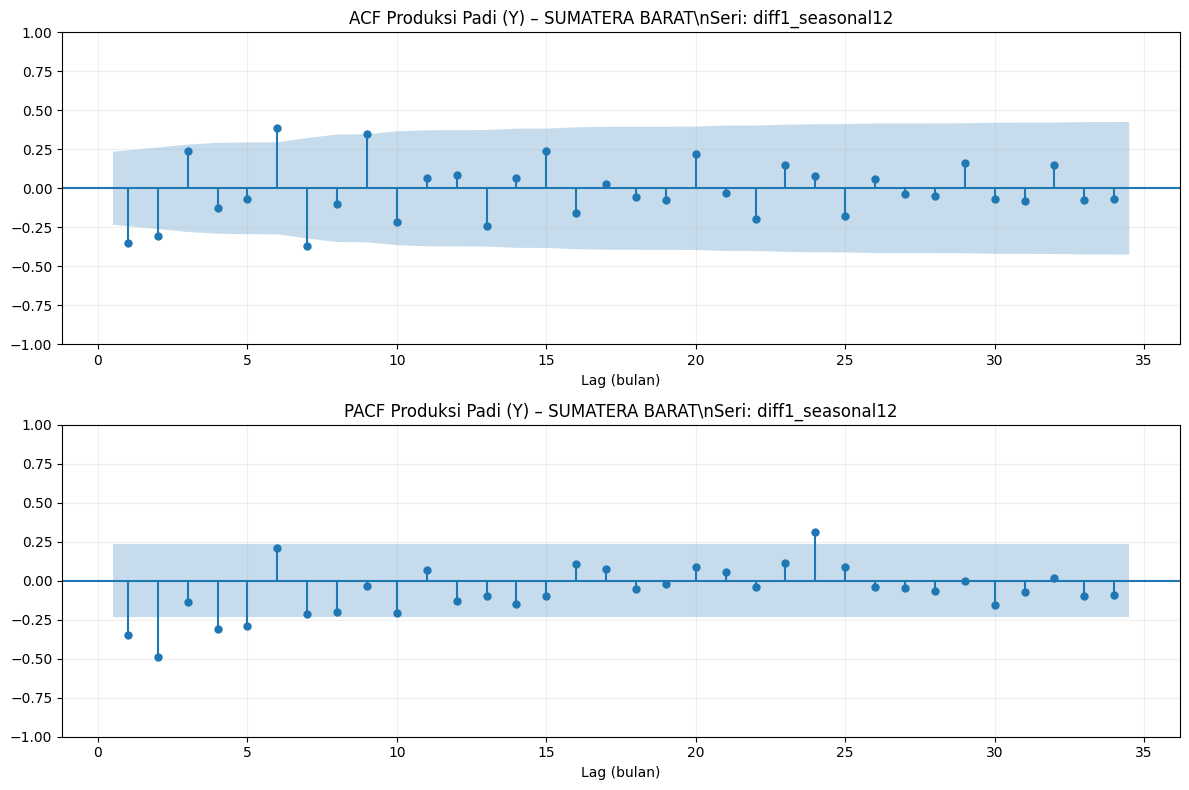

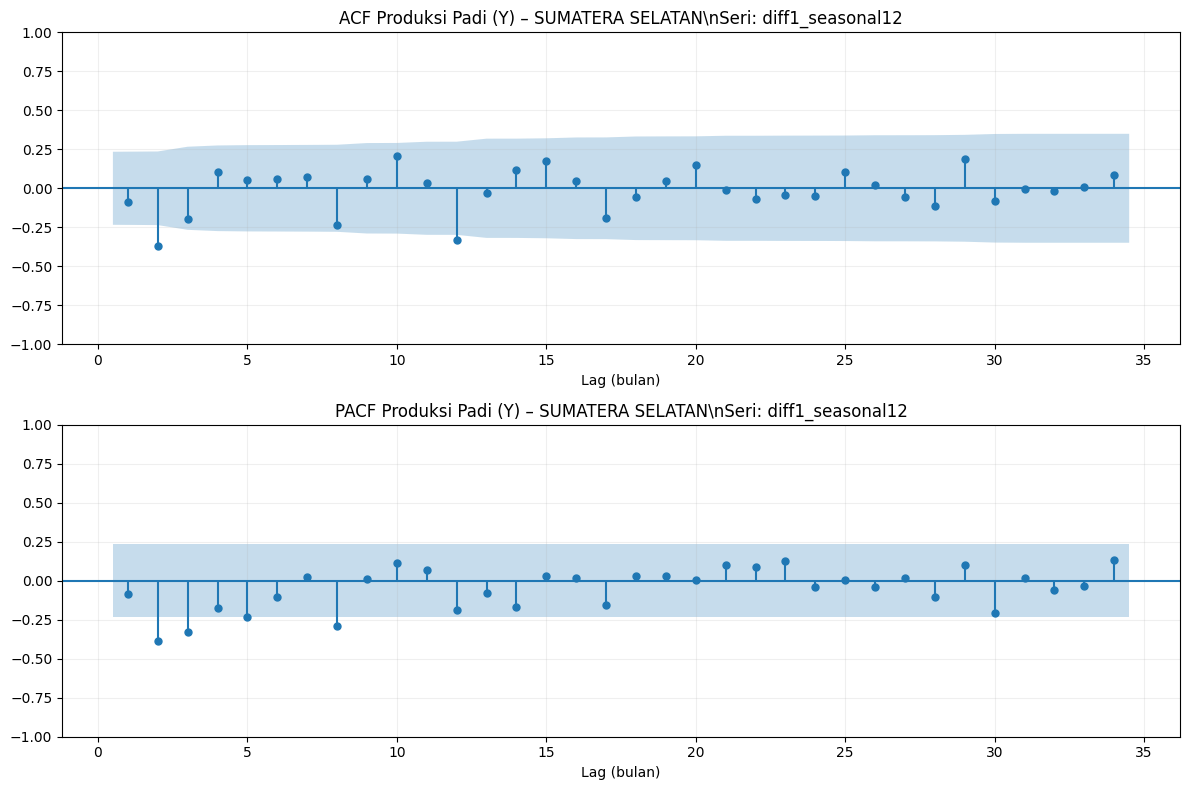

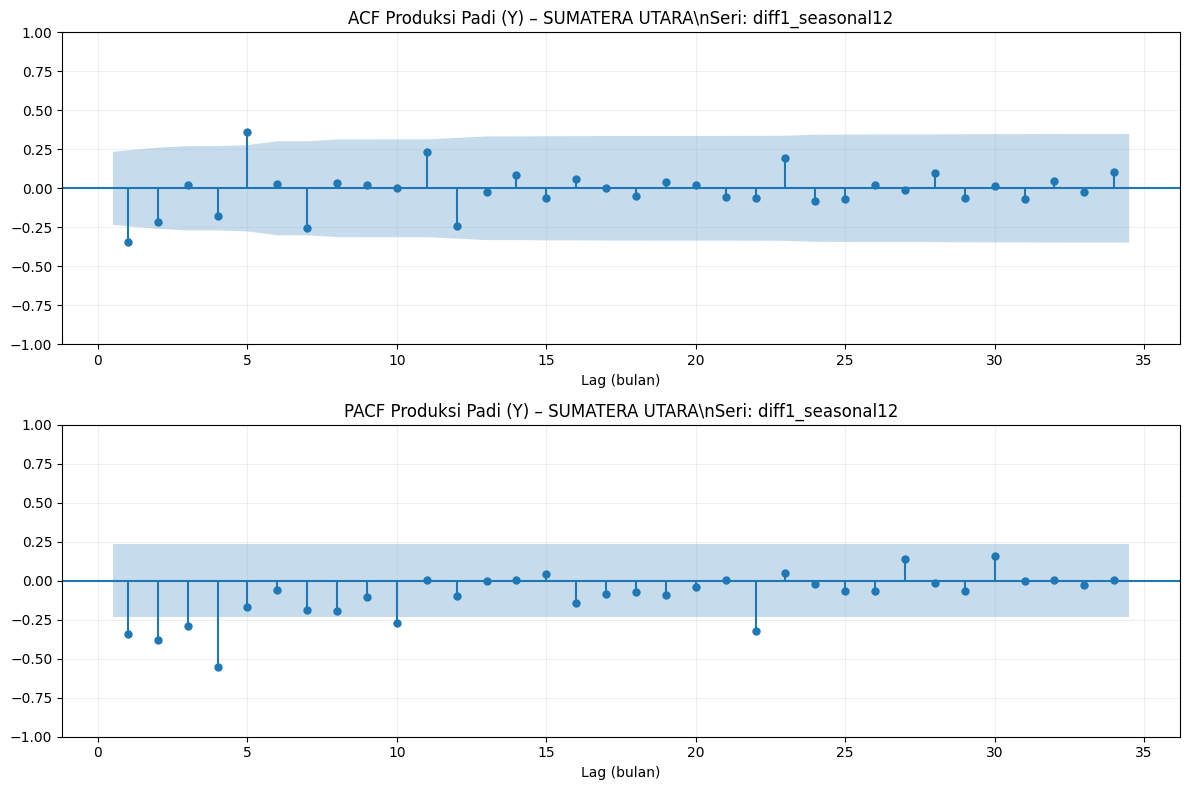

,Provinsi,Seri_yang_dianalisis,Jumlah_observasi_training_setelah_differencing,Lag_maksimum_ditampilkan
0,ACEH,diff1_seasonal12,70,34
1,BALI,diff1_seasonal12,70,34
2,BANTEN,diff1_seasonal12,70,34
3,BENGKULU,diff1_seasonal12,70,34
4,DI YOGYAKARTA,diff1_seasonal12,70,34
5,DKI JAKARTA,diff1_seasonal12,70,34
6,GORONTALO,diff1_seasonal12,70,34
7,JAMBI,diff1_seasonal12,70,34
8,JAWA BARAT,diff1_seasonal12,70,34
9,JAWA TENGAH,diff1_seasonal12,70,34


PDF grafik ACF dan PACF seluruh provinsi tersimpan sebagai: ACF_PACF_Seluruh_Provinsi.pdf


In [9]:
from matplotlib.backends.backend_pdf import PdfPages
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Ubah sesuai hasil uji stasioneritas pada Tahap 4.
ACF_SERIES = 'diff1_seasonal12'  # pilihan: 'diff1' atau 'diff1_seasonal12'
MAX_LAGS = 36

pdf_name = 'ACF_PACF_Seluruh_Provinsi.pdf'
acf_pacf_summary = []

with PdfPages(pdf_name) as pdf:
    for prov in provinces:
        y_train = panel[prov]['train']['Y'].astype(float)

        if ACF_SERIES == 'diff1':
            y_ident = y_train.diff().dropna()
        elif ACF_SERIES == 'diff1_seasonal12':
            y_ident = y_train.diff().diff(SEASONAL_PERIOD).dropna()
        else:
            raise ValueError("ACF_SERIES harus 'diff1' atau 'diff1_seasonal12'.")

        if len(y_ident) < 10:
            print(f"Data terlalu sedikit untuk ACF/PACF: {prov}")
            continue

        lags = min(MAX_LAGS, len(y_ident)//2 - 1, len(y_ident) - 2)

        fig, axes = plt.subplots(2, 1, figsize=(12, 8))
        plot_acf(y_ident, lags=lags, ax=axes[0], zero=False)
        plot_pacf(y_ident, lags=lags, method='ywm', ax=axes[1], zero=False)

        axes[0].set_title(f'ACF Produksi Padi (Y) – {prov}\\nSeri: {ACF_SERIES}')
        axes[1].set_title(f'PACF Produksi Padi (Y) – {prov}\\nSeri: {ACF_SERIES}')
        for ax in axes:
            ax.set_xlabel('Lag (bulan)')
            ax.grid(alpha=.2)

        fig.tight_layout()
        pdf.savefig(fig, bbox_inches='tight')
        plt.show()
        plt.close(fig)

        acf_pacf_summary.append({
            'Provinsi': prov,
            'Seri_yang_dianalisis': ACF_SERIES,
            'Jumlah_observasi_training_setelah_differencing': len(y_ident),
            'Lag_maksimum_ditampilkan': lags
        })

acf_pacf_summary = pd.DataFrame(acf_pacf_summary)
display(acf_pacf_summary)

print(f"PDF grafik ACF dan PACF seluruh provinsi tersimpan sebagai: {pdf_name}")
# Untuk mengunduh PDF dari Google Colab, jalankan:
# from google.colab import files
# files.download(pdf_name)

##6. Fungsi pemilihan SARIMA/SARIMAX berdasarkan AIC

In [11]:
def fit_best_sarimax(y_train, exog_train=None, use_exog=False):
    best = None
    records = []
    for order in ORDER_CANDIDATES:
        for seasonal_order in SEASONAL_CANDIDATES:
            try:
                model = SARIMAX(
                    y_train,
                    exog=exog_train if use_exog else None,
                    order=order,
                    seasonal_order=seasonal_order,
                    trend='c',
                    enforce_stationarity=False,
                    enforce_invertibility=False
                )
                result = model.fit(disp=False, maxiter=150)
                records.append({
                    'order':order, 'seasonal_order':seasonal_order,
                    'AIC':result.aic, 'BIC':result.bic, 'converged':result.mle_retvals.get('converged', True)
                })
                if np.isfinite(result.aic) and (best is None or result.aic < best['result'].aic):
                    best = {'result':result, 'order':order, 'seasonal_order':seasonal_order}
            except Exception as e:
                records.append({'order':order, 'seasonal_order':seasonal_order,
                                'AIC':np.nan, 'BIC':np.nan, 'converged':False})
    if best is None:
        raise RuntimeError("Semua kandidat SARIMAX gagal diestimasi.")
    return best, pd.DataFrame(records)

def scale_exog_train_test(train_df, test_df):
    # Skala dihitung hanya dari training untuk mencegah data leakage.
    scaler = StandardScaler()
    xtr = scaler.fit_transform(train_df[['X1','X2']])
    xte = scaler.transform(test_df[['X1','X2']])
    xtr = pd.DataFrame(xtr, index=train_df.index, columns=['X1','X2'])
    xte = pd.DataFrame(xte, index=test_df.index, columns=['X1','X2'])
    return xtr, xte, scaler


##7. Pendugaan parameter dan diagnostik residual

In [14]:
def residual_diagnostics(result, model_name, province):
    resid = pd.Series(result.resid).dropna()
    # Hilangkan bagian awal yang dapat dipengaruhi inisialisasi model.
    if len(resid) > 15:
        resid = resid.iloc[12:]
    lb_lag = min(12, max(1, len(resid)//5))
    try:
        lb_p = acorr_ljungbox(resid, lags=[lb_lag], return_df=True)['lb_pvalue'].iloc[0]
    except Exception:
        lb_p = np.nan
    try:
        jb_p = jarque_bera(resid).pvalue
    except Exception:
        jb_p = np.nan
    try:
        arch_p = het_arch(resid, nlags=min(12, max(1, len(resid)//5)))[1]
    except Exception:
        arch_p = np.nan
    return {
        'Provinsi':province, 'Metode':model_name,
        'LjungBox_pvalue':lb_p, 'JarqueBera_pvalue':jb_p,
        'ARCH_LM_pvalue':arch_p,
        'LjungBox_tidak_ada_autokorelasi': bool(lb_p > .05) if pd.notna(lb_p) else None
    }

def plot_model_diagnostics(result, title='Diagnostik residual'):
    resid = pd.Series(result.resid).dropna()
    fig, axes = plt.subplots(2, 2, figsize=(13, 8))
    axes[0,0].plot(resid); axes[0,0].set_title('Residual')
    sns.histplot(resid, kde=True, ax=axes[0,1]); axes[0,1].set_title('Distribusi residual')
    plot_acf(resid, lags=min(24, len(resid)//2-1), ax=axes[1,0])
    axes[1,0].set_title('ACF residual')
    from scipy.stats import probplot
    probplot(resid, dist='norm', plot=axes[1,1])
    axes[1,1].set_title('Q-Q plot')
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

##8. Fungsi fitur lag dan Random Forest rekursif

In [13]:
def calendar_features(index):
    month = pd.DatetimeIndex(index).month
    return pd.DataFrame({
        'month_sin': np.sin(2*np.pi*month/12),
        'month_cos': np.cos(2*np.pi*month/12)
    }, index=index)

def make_rf_training_frame(data, target_col='Y', residual_series=None):
    z = data.copy()
    cal = calendar_features(z.index)
    feat = pd.DataFrame(index=z.index)
    if residual_series is None:
        feat['Y_lag1'] = z[target_col].shift(1)
        feat['Y_lag2'] = z[target_col].shift(2)
        feat['Y_lag12'] = z[target_col].shift(12)
    feat['X1'] = z['X1']
    feat['X2'] = z['X2']
    feat['X1_lag1'] = z['X1'].shift(1)
    feat['X2_lag1'] = z['X2'].shift(1)
    feat = feat.join(cal)
    if residual_series is not None:
        r = pd.Series(residual_series, index=z.index)
        feat['resid_lag1'] = r.shift(1)
        feat['resid_lag12'] = r.shift(12)
        target = r
    else:
        target = z[target_col]
    out = feat.copy()
    out['target'] = target
    return out.dropna()

def fit_rf(train_frame):
    X = train_frame.drop(columns='target')
    y = train_frame['target']
    rf = RandomForestRegressor(
        n_estimators=400, max_depth=8, min_samples_leaf=2,
        max_features=0.9, random_state=RANDOM_STATE, n_jobs=-1
    )
    rf.fit(X, y)
    return rf, list(X.columns)

def recursive_rf_forecast(train_df, test_df, rf, feature_cols):
    y_history = list(train_df['Y'].astype(float).values)
    x1_history = list(train_df['X1'].astype(float).values)
    x2_history = list(train_df['X2'].astype(float).values)
    preds = []
    for dt, row in test_df.iterrows():
        month = dt.month
        feats = {
            'Y_lag1': y_history[-1], 'Y_lag2': y_history[-2],
            'Y_lag12': y_history[-12], 'X1': float(row['X1']),
            'X2': float(row['X2']), 'X1_lag1': x1_history[-1],
            'X2_lag1': x2_history[-1],
            'month_sin': np.sin(2*np.pi*month/12),
            'month_cos': np.cos(2*np.pi*month/12)
        }
        Xrow = pd.DataFrame([{c:feats[c] for c in feature_cols}])
        pred = float(rf.predict(Xrow)[0])
        preds.append(pred)
        y_history.append(pred)
        x1_history.append(float(row['X1']))
        x2_history.append(float(row['X2']))
    return pd.Series(preds, index=test_df.index, name='RF')


##9. Pemodelan seluruh provinsi

In [16]:
predictions = []
model_rows = []
diagnostic_rows = []
selected_orders = []
fitted_objects = {}

for i, prov in enumerate(provinces, start=1):
    print(f"[{i}/{len(provinces)}] Memodelkan {prov} ...")
    train = panel[prov]['train']
    test = panel[prov]['test']
    ytr = train['Y']
    yte = test['Y']

    # A. SARIMA
    best_sarima, grid_sarima = fit_best_sarimax(ytr, use_exog=False)
    sarima_res = best_sarima['result']
    pred_sarima = sarima_res.get_forecast(steps=len(test)).predicted_mean
    pred_sarima.index = test.index

    # B. SARIMAX dengan X1 dan X2
    xtr, xte, exog_scaler = scale_exog_train_test(train, test)
    best_sarimax, grid_sarimax = fit_best_sarimax(ytr, xtr, use_exog=True)
    sarimax_res = best_sarimax['result']
    pred_sarimaxx = sarimax_res.get_forecast(steps=len(test), exog=xte).predicted_mean
    pred_sarimaxx.index = test.index

    # C. Random Forest
    rf_train_frame = make_rf_training_frame(train)
    rf_model, rf_features = fit_rf(rf_train_frame)
    pred_rf = recursive_rf_forecast(train, test, rf_model, rf_features)

    # D. Hybrid: SARIMAX + RF koreksi residual
    # Residual one-step-ahead training dari fitted values SARIMAX.
    fitted_mean = pd.Series(sarimax_res.get_prediction(
        start=0, end=len(train)-1, dynamic=False
    ).predicted_mean.values, index=train.index)
    resid_train = train['Y'] - fitted_mean

    hybrid_frame = make_rf_training_frame(train, residual_series=resid_train)
    hybrid_rf, hybrid_features = fit_rf(hybrid_frame)

    # Prediksi residual testing secara rekursif menggunakan lag residual hasil prediksi.
    resid_history = list(resid_train.dropna().astype(float).values)
    hybrid_correction = []
    for dt, row in test.iterrows():
        month = dt.month
        # Untuk lag 12, gunakan residual historis atau koreksi prediksi yang sudah dibuat.
        lag1 = resid_history[-1]
        lag12 = resid_history[-12] if len(resid_history) >= 12 else 0.0
        feats = {
            'Y_lag1': np.nan, 'Y_lag2': np.nan, 'Y_lag12': np.nan,
            'X1': float(row['X1']), 'X2': float(row['X2']),
            'X1_lag1': float(train['X1'].iloc[-1]) if len(hybrid_correction)==0 else float(test['X1'].iloc[len(hybrid_correction)-1]),
            'X2_lag1': float(train['X2'].iloc[-1]) if len(hybrid_correction)==0 else float(test['X2'].iloc[len(hybrid_correction)-1]),
            'month_sin': np.sin(2*np.pi*month/12),
            'month_cos': np.cos(2*np.pi*month/12),
            'resid_lag1': lag1,
            'resid_lag12': lag12
        }
        # Hybrid RF dilatih pada fitur residual + X1/X2 + kalender.
        # Hilangkan fitur lag Y yang tidak relevan untuk model residual.
        residual_features = [c for c in hybrid_features if c not in ['Y_lag1','Y_lag2','Y_lag12']]
        Xrow = pd.DataFrame([{c:feats[c] for c in residual_features}])
        corr = float(hybrid_rf.predict(Xrow)[0])
        hybrid_correction.append(corr)
        resid_history.append(corr)

    pred_hybrid = pd.Series(np.asarray(pred_sarimaxx) + np.asarray(hybrid_correction), index=test.index)

    for method, pred in [
        ('SARIMA', pred_sarima), ('SARIMAX', pred_sarimaxx),
        ('RF', pred_rf), ('Hybrid SARIMAX-RF', pred_hybrid)
    ]:
        for dt, actual, forecast in zip(test.index, yte.values, np.asarray(pred)):
            predictions.append({
                'Provinsi':prov, 'Tanggal':dt, 'Aktual':float(actual),
                'Prediksi':float(forecast), 'Metode':method
            })
        err = yte.values - np.asarray(pred)
        nonzero = np.abs(yte.values) > 1e-8
        mape = np.mean(np.abs(err[nonzero] / yte.values[nonzero]))*100 if nonzero.any() else np.nan
        smape = np.mean(200*np.abs(err)/(np.abs(yte.values)+np.abs(np.asarray(pred))+1e-8))
        model_rows.append({
            'Provinsi':prov, 'Metode':method,
            'RMSE':np.sqrt(np.mean(err**2)),
            'MAE':np.mean(np.abs(err)),
            'MAPE_pct':mape,
            'sMAPE_pct':smape,
            'WAPE_pct':100*np.sum(np.abs(err))/(np.sum(np.abs(yte.values))+1e-8)
        })

    diagnostic_rows.append(residual_diagnostics(sarima_res, 'SARIMA', prov))
    diagnostic_rows.append(residual_diagnostics(sarimax_res, 'SARIMAX', prov))
    selected_orders.append({
        'Provinsi':prov,
        'SARIMA_order':str(best_sarima['order']),
        'SARIMA_seasonal_order':str(best_sarima['seasonal_order']),
        'SARIMA_AIC':sarima_res.aic,
        'SARIMA_BIC':sarima_res.bic,
        'SARIMAX_order':str(best_sarimax['order']),
        'SARIMAX_seasonal_order':str(best_sarimax['seasonal_order']),
        'SARIMAX_AIC':sarimax_res.aic,
        'SARIMAX_BIC':sarimax_res.bic
    })
    fitted_objects[prov] = {
        'sarima':sarima_res, 'sarimax':sarimax_res,
        'rf':rf_model, 'hybrid_rf':hybrid_rf,
        'rf_features':rf_features, 'hybrid_features':hybrid_features,
        'exog_scaler':exog_scaler
    }

pred_df = pd.DataFrame(predictions)
metrics_df = pd.DataFrame(model_rows)
diagnostics_df = pd.DataFrame(diagnostic_rows)
orders_df = pd.DataFrame(selected_orders)

print("Pemodelan selesai.")

[1/38] Memodelkan ACEH ...
[2/38] Memodelkan BALI ...
[3/38] Memodelkan BANTEN ...
[4/38] Memodelkan BENGKULU ...
[5/38] Memodelkan DI YOGYAKARTA ...
[6/38] Memodelkan DKI JAKARTA ...
[7/38] Memodelkan GORONTALO ...
[8/38] Memodelkan JAMBI ...
[9/38] Memodelkan JAWA BARAT ...
[10/38] Memodelkan JAWA TENGAH ...
[11/38] Memodelkan JAWA TIMUR ...
[12/38] Memodelkan KALIMANTAN BARAT ...
[13/38] Memodelkan KALIMANTAN SELATAN ...
[14/38] Memodelkan KALIMANTAN TENGAH ...
[15/38] Memodelkan KALIMANTAN TIMUR ...
[16/38] Memodelkan KALIMANTAN UTARA ...
[17/38] Memodelkan KEPULAUAN BANGKA BELITUNG ...
[18/38] Memodelkan KEPULAUAN RIAU ...
[19/38] Memodelkan LAMPUNG ...
[20/38] Memodelkan MALUKU ...
[21/38] Memodelkan MALUKU UTARA ...
[22/38] Memodelkan NUSA TENGGARA BARAT ...
[23/38] Memodelkan NUSA TENGGARA TIMUR ...
[24/38] Memodelkan PAPUA ...
[25/38] Memodelkan PAPUA BARAT ...
[26/38] Memodelkan PAPUA BARAT DAYA ...
[27/38] Memodelkan PAPUA PENGUNUNGAN ...
[28/38] Memodelkan PAPUA SELATAN ...

##10. Ringkasan hasil, evaluasi, dan model terbaik

In [17]:
# Rata-rata metrik antarprovinsi (setiap provinsi diberi bobot sama).
summary_metrics = metrics_df.groupby('Metode')[['RMSE','MAE','MAPE_pct','sMAPE_pct','WAPE_pct']].mean().sort_values('RMSE')
display(summary_metrics)

# Metrik agregat seluruh observasi testing (provinsi dengan skala produksi lebih besar
# akan memberi kontribusi lebih besar pada agregat).
pooled_rows = []
for method, g in pred_df.groupby('Metode'):
    err = g['Aktual'].values - g['Prediksi'].values
    nz = np.abs(g['Aktual'].values) > 1e-8
    pooled_rows.append({
        'Metode':method,
        'RMSE_pooled':np.sqrt(np.mean(err**2)),
        'MAE_pooled':np.mean(np.abs(err)),
        'MAPE_pooled_pct':np.mean(np.abs(err[nz]/g['Aktual'].values[nz]))*100,
        'WAPE_pooled_pct':100*np.sum(np.abs(err))/(np.sum(np.abs(g['Aktual'].values))+1e-8)
    })
pooled_metrics = pd.DataFrame(pooled_rows).sort_values('RMSE_pooled')
display(pooled_metrics)

# Metode terbaik untuk setiap provinsi berdasarkan RMSE.
best_by_province = metrics_df.loc[metrics_df.groupby('Provinsi')['RMSE'].idxmin()].sort_values('Provinsi')
display(best_by_province)

# Diagnostik residual SARIMA dan SARIMAX.
display(diagnostics_df)
display(orders_df)


,RMSE,MAE,MAPE_pct,sMAPE_pct,WAPE_pct
Metode,,,,,
Hybrid SARIMAX-RF,10124.905383,8307.659117,151.333477,31.578631,36.616019
SARIMAX,10181.161174,8504.279683,150.813156,29.980135,35.989654
RF,11861.728800,7906.822630,14.867194,15.804368,12.232247
SARIMA,43096.964978,33999.057107,616.417071,60.313990,273.729636


,Metode,RMSE_pooled,MAE_pooled,MAPE_pooled_pct,WAPE_pooled_pct
0,Hybrid SARIMAX-RF,17870.902678,8307.659117,143.445713,6.248513
3,SARIMAX,18219.337206,8504.279683,143.569648,6.396399
1,RF,19661.750262,7906.822630,14.410305,5.947029
2,SARIMA,70991.988122,33999.057107,608.490904,25.572013


,Provinsi,Metode,RMSE,MAE,MAPE_pct,sMAPE_pct,WAPE_pct
1,ACEH,SARIMAX,10065.735716,8698.028427,19.509514,14.651563,6.985264
6,BALI,RF,1995.490619,1619.934351,3.920001,3.858062,3.383165
11,BANTEN,Hybrid SARIMAX-RF,16081.780047,13119.153762,12.775645,13.732549,8.555675
14,BENGKULU,RF,2213.017252,1510.368193,6.602198,6.894161,6.865536
18,DI YOGYAKARTA,RF,3815.654072,3206.820523,9.569429,9.237281,6.335873
22,DKI JAKARTA,RF,11.351524,10.303102,18.980610,33.744018,9.169335
25,GORONTALO,SARIMAX,2623.894182,2090.743844,12.701040,14.735665,8.732388
31,JAMBI,Hybrid SARIMAX-RF,2440.719242,1699.823725,5.623592,5.485841,5.767294
34,JAWA BARAT,RF,38601.358128,28605.226020,3.691231,3.738035,3.446748
39,JAWA TENGAH,Hybrid SARIMAX-RF,40943.473249,35984.086740,5.536142,5.336092,4.464572


,Provinsi,Metode,LjungBox_pvalue,JarqueBera_pvalue,ARCH_LM_pvalue,LjungBox_tidak_ada_autokorelasi
0,ACEH,SARIMA,0.023467,2.881052e-02,6.684318e-01,False
1,ACEH,SARIMAX,0.348359,2.881698e-253,1.540128e-03,True
2,BALI,SARIMA,0.167411,1.989340e-02,2.119512e-02,True
3,BALI,SARIMAX,0.847921,0.000000e+00,1.334589e-06,True
4,BANTEN,SARIMA,0.000105,5.786666e-03,1.240535e-01,False
...,...,...,...,...,...,...
71,SUMATERA BARAT,SARIMAX,0.658850,0.000000e+00,1.462986e-07,True
72,SUMATERA SELATAN,SARIMA,0.241764,7.316060e-02,9.021945e-01,True
73,SUMATERA SELATAN,SARIMAX,0.089157,2.056316e-203,3.107897e-04,True
74,SUMATERA UTARA,SARIMA,0.056284,8.233780e-01,3.449811e-01,True


,Provinsi,SARIMA_order,SARIMA_seasonal_order,SARIMA_AIC,SARIMA_BIC,SARIMAX_order,SARIMAX_seasonal_order,SARIMAX_AIC,SARIMAX_BIC
0,ACEH,"(0, 1, 1)","(1, 1, 1, 12)",1413.266861,1423.393620,"(1, 1, 1)","(0, 1, 1, 12)",1180.093098,1194.270560
1,BALI,"(0, 1, 1)","(0, 1, 1, 12)",1232.142796,1240.244203,"(1, 1, 1)","(0, 1, 1, 12)",992.809523,1006.986985
2,BANTEN,"(0, 1, 1)","(0, 1, 1, 12)",1448.340665,1456.442072,"(0, 1, 1)","(0, 1, 1, 12)",1168.021477,1180.173587
3,BENGKULU,"(1, 1, 1)","(0, 1, 1, 12)",1205.837578,1215.964337,"(0, 1, 1)","(0, 1, 1, 12)",1020.669969,1032.822079
4,DI YOGYAKARTA,"(0, 1, 1)","(0, 1, 1, 12)",1311.585853,1319.687260,"(1, 1, 1)","(0, 1, 1, 12)",1106.616345,1120.793807
5,DKI JAKARTA,"(0, 1, 1)","(1, 1, 1, 12)",785.441769,795.568528,"(0, 1, 1)","(0, 1, 1, 12)",641.775719,653.927829
6,GORONTALO,"(1, 1, 1)","(0, 1, 1, 12)",1233.764353,1243.891111,"(1, 1, 1)","(1, 1, 1, 12)",1006.629964,1022.832778
7,JAMBI,"(0, 1, 1)","(0, 1, 1, 12)",1192.864944,1200.966351,"(1, 1, 1)","(0, 1, 1, 12)",972.009238,986.186700
8,JAWA BARAT,"(0, 1, 1)","(0, 1, 1, 12)",1568.201920,1576.303327,"(0, 1, 1)","(0, 1, 1, 12)",1295.845083,1307.997193
9,JAWA TENGAH,"(0, 1, 1)","(0, 1, 1, 12)",1587.915108,1596.016515,"(0, 1, 1)","(0, 1, 1, 12)",1314.186193,1326.338303


##11. Visualisasi aktual vs prediksi

Provinsi yang ditampilkan: ACEH


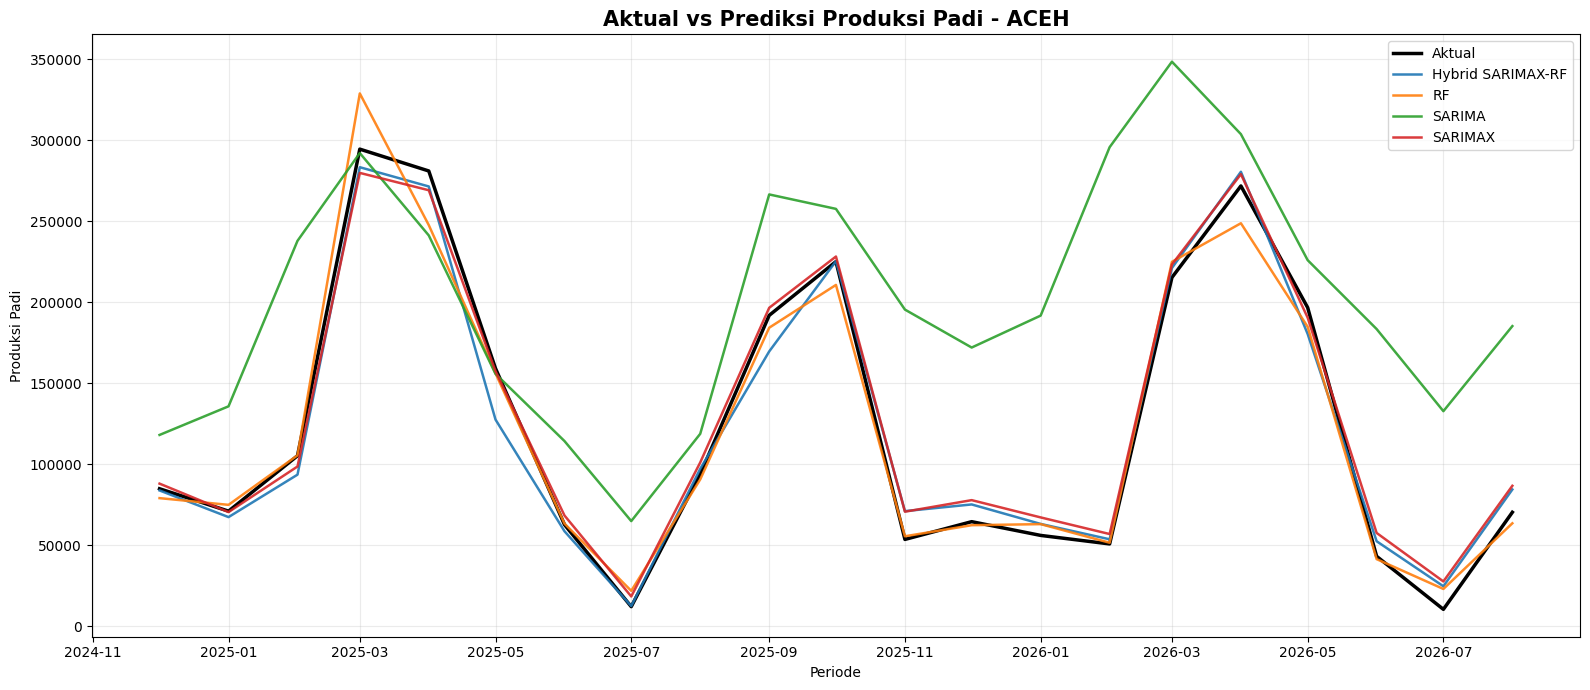

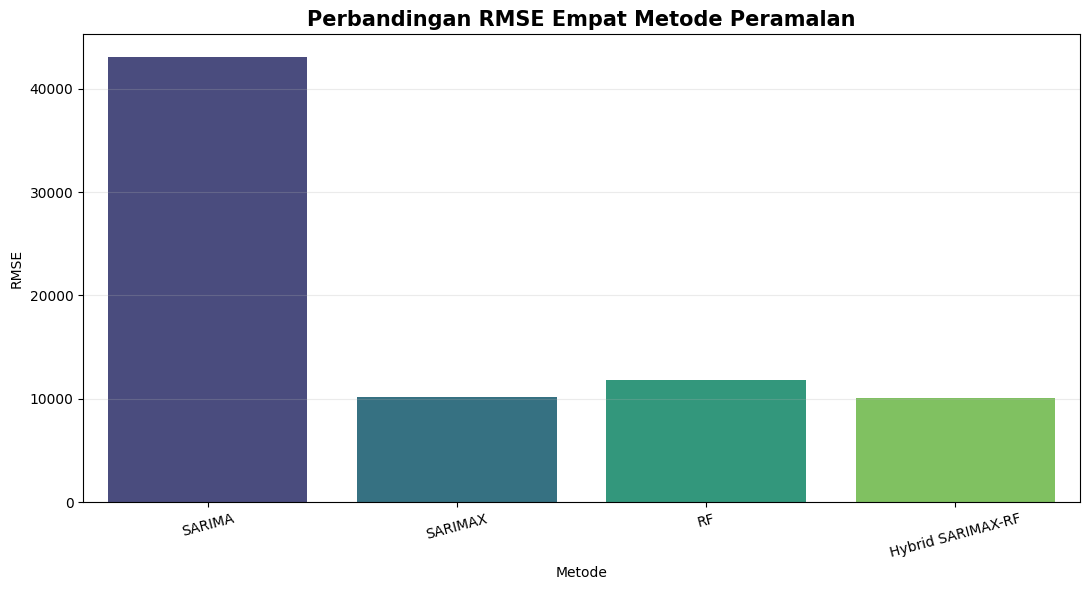

In [25]:
# ==========================================
# TAHAP 11. VISUALISASI HASIL PERAMALAN
# ==========================================

# Pilih provinsi yang tersedia secara otomatis
prov_plot = provinces[0]

print("Provinsi yang ditampilkan:", prov_plot)

# Mengambil data hasil prediksi
plot_data = pred_df[
    pred_df['Provinsi'] == prov_plot
].copy()

# Grafik 1: Aktual vs Prediksi
plt.figure(figsize=(16, 7))

actual_once = (
    plot_data.drop_duplicates('Tanggal')
    .sort_values('Tanggal')
)

plt.plot(
    actual_once['Tanggal'],
    actual_once['Aktual'],
    label='Aktual',
    color='black',
    linewidth=2.5
)

for method, gm in plot_data.groupby('Metode'):
    gm = gm.sort_values('Tanggal')
    plt.plot(
        gm['Tanggal'],
        gm['Prediksi'],
        label=method,
        linewidth=1.8,
        alpha=0.9
    )

plt.title(
    f'Aktual vs Prediksi Produksi Padi - {prov_plot}',
    fontsize=15,
    fontweight='bold'
)
plt.xlabel('Periode')
plt.ylabel('Produksi Padi')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


# Grafik 2: Perbandingan RMSE empat metode
plt.figure(figsize=(11, 6))

sns.barplot(
    data=metrics_df,
    x='Metode',
    y='RMSE',
    hue='Metode',
    palette='viridis',
    legend=False,
    errorbar=None
)

plt.title(
    'Perbandingan RMSE Empat Metode Peramalan',
    fontsize=15,
    fontweight='bold'
)
plt.xlabel('Metode')
plt.ylabel('RMSE')
plt.xticks(rotation=15)
plt.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()


##12. Peramalan periode mendatang (opsional)

In [26]:
H = 12
future_forecasts = []

for prov in provinces:
    full_series = panel[prov]['full']
    # Refit ulang menggunakan seluruh observasi yang tersedia sampai akhir dataset.
    best_full, _ = fit_best_sarimax(full_series['Y'], use_exog=False)
    full_model = best_full['result']
    fc = full_model.get_forecast(steps=H).predicted_mean
    future_dates = pd.date_range(
        full_series.index.max() + pd.offsets.MonthBegin(1),
        periods=H, freq='MS'
    )
    for dt, val in zip(future_dates, np.asarray(fc)):
        future_forecasts.append({
            'Provinsi':prov, 'Tanggal':dt,
            'SARIMA_forecast':float(val),
            'order':str(best_full['order']),
            'seasonal_order':str(best_full['seasonal_order'])
        })

future_sarima_df = pd.DataFrame(future_forecasts)
display(future_sarima_df.head(20))

,Provinsi,Tanggal,SARIMA_forecast,order,seasonal_order
0,ACEH,2026-09-01,179640.334415,"(0, 1, 1)","(1, 1, 1, 12)"
1,ACEH,2026-10-01,223889.060053,"(0, 1, 1)","(1, 1, 1, 12)"
2,ACEH,2026-11-01,45252.491216,"(0, 1, 1)","(1, 1, 1, 12)"
3,ACEH,2026-12-01,70051.350203,"(0, 1, 1)","(1, 1, 1, 12)"
4,ACEH,2027-01-01,52203.177315,"(0, 1, 1)","(1, 1, 1, 12)"
5,ACEH,2027-02-01,45318.334844,"(0, 1, 1)","(1, 1, 1, 12)"
6,ACEH,2027-03-01,220196.178745,"(0, 1, 1)","(1, 1, 1, 12)"
7,ACEH,2027-04-01,268057.225392,"(0, 1, 1)","(1, 1, 1, 12)"
8,ACEH,2027-05-01,184291.992956,"(0, 1, 1)","(1, 1, 1, 12)"
9,ACEH,2027-06-01,29556.930889,"(0, 1, 1)","(1, 1, 1, 12)"


##13. Ekspor hasil analisis

In [27]:
with pd.ExcelWriter('Hasil_Analisis_Peramalan_Padi_Panel.xlsx', engine='openpyxl') as writer:
    split_table.to_excel(writer, sheet_name='Pembagian_Data', index=False)
    stationarity_table.to_excel(writer, sheet_name='Stasioneritas', index=False)
    orders_df.to_excel(writer, sheet_name='Orde_Model', index=False)
    diagnostics_df.to_excel(writer, sheet_name='Diagnostik_Residual', index=False)
    metrics_df.to_excel(writer, sheet_name='Metrik_Per_Provinsi', index=False)
    summary_metrics.to_excel(writer, sheet_name='Rata_Rata_Metrik')
    pooled_metrics.to_excel(writer, sheet_name='Metrik_Agregat', index=False)
    best_by_province.to_excel(writer, sheet_name='Model_Terbaik', index=False)
    pred_df.to_excel(writer, sheet_name='Prediksi_Testing', index=False)
    future_sarima_df.to_excel(writer, sheet_name='Forecast_SARIMA', index=False)

print("File hasil berhasil dibuat.")
files.download('Hasil_Analisis_Peramalan_Padi_Panel.xlsx')


File hasil berhasil dibuat.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>